# Proyecto final – Análisis Bayesiano de Datos
## Replicación de Polo et al. (2022): modelo espacial bayesiano de la letalidad por COVID-19 en Colombia

**Autora:** Walys Vera Herrera · Universidad de Antioquia

Este notebook reproduce el análisis del artículo *Bayesian spatial modeling of COVID-19 case-fatality rate inequalities* (Polo et al., 2022, *Spatial and Spatio-temporal Epidemiology*, 41, 100494).

**Orden del análisis** (el mismo del artículo):

| Paso | Qué se hace | Sección de la guía de lectura |
|---|---|---|
| 1 | Cargar los datos (Tablas 1 y 2 del artículo) | 3. Datos |
| 2 | Construir la matriz de vecinos $W$ | 4.3 |
| 3 | Modelo Poisson frecuentista (GLM), como método tradicional | 4.1 |
| 4 | I de Moran sobre los residuos | 4.2 |
| 5 | Modelo Poisson bayesiano **sin** efecto espacial (Metropolis–Hastings) | 4.1 |
| 6 | Modelo CAR de Leroux (Metropolis dentro de Gibbs) | 4.3 – 4.4 |
| 7 | Convergencia: trazas, $\hat R$, tamaño efectivo, Geweke | 5.2 |
| 8 | Resultados: tabla posterior y riesgos relativos | 4.5, 5.2, 5.3 |
| 9 | Comparación de modelos (DIC) y sensibilidad a la priori | — |
| 10 | Gráficos para el informe | — |

Para correrlo: **Entorno de ejecución → Ejecutar todas**. Todo tarda unos pocos minutos.

## 0. Librerías

In [1]:
# ==============================================================
# Paquetes usados en todo el cuaderno
#   numpy / pandas  -> manejo de datos y álgebra matricial
#   matplotlib      -> gráficos
#   scipy           -> distribuciones y log-gamma (verosimilitud Poisson)
#   statsmodels     -> GLM Poisson frecuentista (punto de comparación)
# ==============================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from io import StringIO
from scipy import stats
from scipy.special import gammaln
import statsmodels.api as sm

# Configuración de la resolución de los gráficos y de la impresión de números
plt.rcParams["figure.dpi"] = 110
np.set_printoptions(suppress=True)

## 1. Datos

Los datos vienen de las **Tablas 1 y 2** del artículo, que tienen la información completa de los 33 departamentos (32 departamentos + Bogotá D.C.), del 16 de marzo al 4 de octubre de 2020. 

| Columna | Significado |
|---|---|
| `Y` | Muertes observadas por COVID-19 (INS) |
| `E` | Muertes **esperadas** si el departamento tuviera la letalidad nacional (3.4 %) |
| `SCFR` | Letalidad estandarizada: $Y/E$ |
| `HMPI` | IPM – dimensión salud |
| `EMPI` | IPM – dimensión educación |
| `WMPI` | IPM – dimensión trabajo |
| `DMPI` | IPM – dimensión vivienda |
| `YMPI` | IPM – dimensión niñez y juventud |

In [2]:
# Datos de los 33 departamentos transcritos de las Tablas 1 y 2 de Polo et al. (2022).
#   Y = muertes, E = muertes esperadas con la letalidad nacional,
#   CFR = letalidad bruta (%), SCFR = letalidad estandarizada (Y/E),
#   HMPI, DMPI, EMPI, WMPI, YMPI = dimensiones del IPM (salud, vivienda,
#   educación, trabajo, niñez y juventud), en puntos porcentuales.
datos_csv = """
codigo,departamento,area_km2,poblacion,casos,Y,E,CFR,SCFR,HMPI,DMPI,EMPI,WMPI,YMPI
91,Amazonas,109665,79020,2746,120,93,4.37,1.29,1.6,6.3,10.5,11.1,5.3
5,Antioquia,63612,6677930,120270,2793,4070,2.33,0.69,1.4,2.6,5.6,4.9,2.6
81,Arauca,23818,294206,1938,68,65,3.53,1.04,3.9,4.9,9.5,8.8,4.6
8,Atlántico,3388,2722128,67961,3133,2297,4.64,1.36,3.6,2.0,5.7,5.3,3.4
11,Bogotá D.C.,1775,7743955,274587,7345,9296,2.69,0.79,0.8,0.3,1.2,1.4,0.7
13,Bolívar,25978,2180976,29447,817,996,2.79,0.82,3.2,5.8,10.8,8.2,4.4
15,Boyacá,23189,1242731,7938,196,268,2.49,0.73,1.9,1.6,5.9,4.9,2.2
17,Caldas,7888,1018453,6494,177,218,2.76,0.81,1.7,1.2,5.7,4.5,2.1
18,Caquetá,88965,410521,8745,345,295,3.97,1.17,2.7,3.4,9.6,8.1,4.8
85,Casanare,44640,435195,2641,72,89,2.74,0.81,2.8,1.9,6.1,5.1,3.2
19,Cauca,29308,1491937,9989,322,336,3.26,0.96,3.2,3.5,10.1,7.6,4.2
20,Cesar,22905,1295387,20943,727,708,3.49,1.03,5.1,4.2,10.4,8.3,5.3
27,Chocó,46530,544764,4034,161,136,4.02,1.18,3.7,8.5,15.5,11.4,5.9
23,Córdoba,25020,1828947,25562,1613,827,6.63,1.95,2.5,6.9,13.5,9.2,4.6
25,Cundinamarca,22633,3242999,34756,1127,1176,3.26,0.96,1.7,0.9,3.9,3.4,1.6
94,Guainía,72238,50636,960,18,33,1.88,0.55,3.1,15.8,17.8,20.4,7.9
95,Guaviare,53460,86657,944,20,32,2.13,0.63,3.4,6.4,10.3,9.0,4.4
41,Huila,19890,1122622,12697,491,429,3.89,1.14,1.6,2.0,6.7,5.6,3.3
44,La Guajira,20848,965718,8320,380,282,4.58,1.35,6.0,11.3,15.8,11.8,6.6
47,Magdalena,23188,1427026,15591,896,568,5.79,1.70,5.4,6.1,12.2,9.4,5.4
50,Meta,85635,1063454,16785,464,568,2.78,0.82,2.0,1.5,5.1,4.5,2.5
52,Nariño,33268,1627589,18745,741,633,3.98,1.17,4.9,4.3,11.1,8.3,4.8
54,Norte de Santander,21658,1620318,16540,1012,558,6.16,1.81,6.1,3.2,9.2,8.2,4.7
86,Putumayo,24885,359127,3876,193,145,5.00,1.47,2.1,3.6,8.3,7.5,3.5
63,Quindío,1845,555401,4247,145,144,3.42,1.01,2.9,0.7,5.6,4.8,2.1
66,Risaralda,4140,961055,11806,335,399,2.85,0.84,1.4,0.9,4.5,3.6,2.1
88,San Andrés,52,63692,1504,28,51,1.87,0.55,7.6,2.8,5.8,2.6,6.3
68,Santander,30537,2280908,32582,1548,1101,4.78,1.41,1.5,1.2,4.6,3.8,1.9
70,Sucre,10917,949252,14029,620,474,4.45,1.31,4.7,5.5,14.6,9.6,5.2
73,Tolima,23562,1339998,12864,423,434,3.32,0.98,3.4,2.2,7.8,6.3,3.6
76,Valle del Cauca,22140,4532152,65045,2532,2197,3.92,1.15,2.2,0.9,4.3,3.8,2.3
97,Vaupés,54135,44712,863,12,29,1.40,0.41,1.2,14.3,15.9,21.4,6.5
99,Vichada,100242,112958,556,8,19,1.44,0.42,3.4,13.4,15.4,15.2,7.3
"""

# Convertir el texto en una tabla de pandas
datos = pd.read_csv(StringIO(datos_csv))
datos.to_csv("datos_polo2022.csv", index=False)   # se guarda una copia para entregar con el código
datos

,codigo,departamento,area_km2,poblacion,casos,Y,E,CFR,SCFR,HMPI,DMPI,EMPI,WMPI,YMPI
0,91,Amazonas,109665,79020,2746,120,93,4.37,1.29,1.6,6.3,10.5,11.1,5.3
1,5,Antioquia,63612,6677930,120270,2793,4070,2.33,0.69,1.4,2.6,5.6,4.9,2.6
2,81,Arauca,23818,294206,1938,68,65,3.53,1.04,3.9,4.9,9.5,8.8,4.6
3,8,Atlántico,3388,2722128,67961,3133,2297,4.64,1.36,3.6,2.0,5.7,5.3,3.4
4,11,Bogotá D.C.,1775,7743955,274587,7345,9296,2.69,0.79,0.8,0.3,1.2,1.4,0.7
5,13,Bolívar,25978,2180976,29447,817,996,2.79,0.82,3.2,5.8,10.8,8.2,4.4
6,15,Boyacá,23189,1242731,7938,196,268,2.49,0.73,1.9,1.6,5.9,4.9,2.2
7,17,Caldas,7888,1018453,6494,177,218,2.76,0.81,1.7,1.2,5.7,4.5,2.1
8,18,Caquetá,88965,410521,8745,345,295,3.97,1.17,2.7,3.4,9.6,8.1,4.8
9,85,Casanare,44640,435195,2641,72,89,2.74,0.81,2.8,1.9,6.1,5.1,3.2


**Comprobación:** el SCFR debe ser igual a $Y/E$ (ecuación 3 del artículo). También se revisa que el total de muertes sea 28 882, como dice el artículo.

In [3]:
# Verificación de los datos: recalcular SCFR = Y / E y comparar con el valor publicado
datos["SCFR_calculado"] = (datos["Y"] / datos["E"]).round(2)
# El total debe coincidir con el reportado en el artículo (28 882 muertes)
print("Total de muertes:", datos["Y"].sum())
# Departamentos donde el SCFR publicado difiere del calculado en más de 0.02
diferentes = datos[(datos["SCFR"] - datos["SCFR_calculado"]).abs() > 0.02]
print("Departamentos donde la Tabla 1 no coincide con Y/E:")
print(diferentes[["departamento", "Y", "E", "SCFR", "SCFR_calculado"]])

Total de muertes: 28882
Departamentos donde la Tabla 1 no coincide con Y/E:
   departamento    Y    E  SCFR  SCFR_calculado
19    Magdalena  896  568  1.70            1.58
23     Putumayo  193  145  1.47            1.33


> **Nota:** en Magdalena y Putumayo el SCFR que reporta la Tabla 1 no coincide con $Y/E$. En el modelo se usan $Y$ y $E$ directamente, así que esto no afecta el ajuste, pero es una inconsistencia del artículo.

### Estadística descriptiva (Tabla 1 del informe)

In [4]:
# Nombres de las cinco dimensiones del IPM (covariables del modelo)
covariables = ["HMPI", "EMPI", "WMPI", "DMPI", "YMPI"]
nombres_cov = {"HMPI": "Salud", "EMPI": "Educación", "WMPI": "Trabajo", "DMPI": "Vivienda", "YMPI": "Niñez y juventud"}

# Estadística descriptiva del SCFR y de las covariables
descriptiva = datos[["SCFR_calculado"] + covariables].describe().T[["mean", "std", "min", "max"]]
descriptiva.columns = ["Media", "Desv. estándar", "Mínimo", "Máximo"]
descriptiva.round(2)

,Media,Desv. estándar,Mínimo,Máximo
SCFR_calculado,1.03,0.37,0.41,1.95
HMPI,3.11,1.63,0.80,7.60
EMPI,9.06,4.24,1.20,17.80
WMPI,7.82,4.52,1.40,21.40
DMPI,4.55,4.07,0.30,15.80
YMPI,4.10,1.78,0.70,7.90


### Correlación entre las dimensiones del IPM

Si las covariables están muy correlacionadas entre sí (**multicolinealidad**), al modelo le cuesta separar el efecto de cada una: los coeficientes pueden cambiar de signo y sus intervalos se vuelven anchos. Es importante tenerlo en cuenta al interpretar.

In [5]:
# Matriz de correlación entre las dimensiones del IPM (revisa multicolinealidad)
datos[covariables].corr().round(2)

,HMPI,EMPI,WMPI,DMPI,YMPI
HMPI,1.00,0.38,0.13,0.21,0.58
EMPI,0.38,1.00,0.90,0.91,0.90
WMPI,0.13,0.90,1.00,0.95,0.82
DMPI,0.21,0.91,0.95,1.00,0.86
YMPI,0.58,0.90,0.82,0.86,1.00


## 2. Matriz de vecinos $W$

$w_{kj} = 1$ si los departamentos $k$ y $j$ **comparten frontera**, y $0$ si no. Se construyó a partir del mapa político de Colombia.

**San Andrés** es una isla: no tiene vecinos terrestres. En el modelo de Leroux esto no es problema: su efecto espacial queda con media 0 y varianza $\tau^2/(1-\rho)$, es decir, no se "amarra" a ningún departamento.

In [6]:
# ==============================================================
# Matriz de vecindad W por contigüidad: w_kj = 1 si los departamentos
# k y j comparten frontera. La lista se verificó con el mapa de Colombia.
# San Andrés es una isla: no tiene vecinos.
# ==============================================================
VECINOS = {
    "Amazonas": ["Caquetá", "Putumayo", "Vaupés"],
    "Antioquia": ["Córdoba", "Bolívar", "Santander", "Boyacá", "Caldas", "Risaralda", "Chocó", "Cundinamarca"],
    "Arauca": ["Boyacá", "Casanare", "Vichada"],
    "Atlántico": ["Bolívar", "Magdalena"],
    "Bogotá D.C.": ["Cundinamarca", "Meta", "Huila"],
    "Bolívar": ["Atlántico", "Magdalena", "Cesar", "Santander", "Antioquia", "Córdoba", "Sucre"],
    "Boyacá": ["Santander", "Norte de Santander", "Arauca", "Casanare", "Cundinamarca", "Antioquia"],
    "Caldas": ["Antioquia", "Cundinamarca", "Tolima", "Risaralda"],
    "Caquetá": ["Meta", "Guaviare", "Vaupés", "Amazonas", "Putumayo", "Cauca", "Huila"],
    "Casanare": ["Arauca", "Vichada", "Meta", "Boyacá", "Cundinamarca"],
    "Cauca": ["Valle del Cauca", "Tolima", "Huila", "Caquetá", "Putumayo", "Nariño"],
    "Cesar": ["La Guajira", "Magdalena", "Bolívar", "Santander", "Norte de Santander"],
    "Chocó": ["Antioquia", "Risaralda", "Valle del Cauca"],
    "Córdoba": ["Antioquia", "Bolívar", "Sucre"],
    "Cundinamarca": ["Boyacá", "Caldas", "Tolima", "Huila", "Meta", "Bogotá D.C.", "Antioquia", "Casanare"],
    "Guainía": ["Vichada", "Guaviare", "Vaupés"],
    "Guaviare": ["Meta", "Vichada", "Guainía", "Vaupés", "Caquetá"],
    "Huila": ["Tolima", "Cundinamarca", "Bogotá D.C.", "Meta", "Caquetá", "Cauca"],
    "La Guajira": ["Magdalena", "Cesar"],
    "Magdalena": ["Atlántico", "Bolívar", "Cesar", "La Guajira"],
    "Meta": ["Cundinamarca", "Bogotá D.C.", "Casanare", "Vichada", "Guaviare", "Caquetá", "Huila"],
    "Nariño": ["Cauca", "Putumayo"],
    "Norte de Santander": ["Cesar", "Santander", "Boyacá"],
    "Putumayo": ["Nariño", "Cauca", "Caquetá", "Amazonas"],
    "Quindío": ["Risaralda", "Tolima", "Valle del Cauca"],
    "Risaralda": ["Antioquia", "Caldas", "Tolima", "Quindío", "Valle del Cauca", "Chocó"],
    "San Andrés": [],
    "Santander": ["Bolívar", "Cesar", "Norte de Santander", "Boyacá", "Antioquia"],
    "Sucre": ["Bolívar", "Córdoba"],
    "Tolima": ["Caldas", "Cundinamarca", "Huila", "Cauca", "Valle del Cauca", "Quindío", "Risaralda"],
    "Valle del Cauca": ["Chocó", "Risaralda", "Quindío", "Tolima", "Cauca"],
    "Vaupés": ["Guainía", "Guaviare", "Caquetá", "Amazonas"],
    "Vichada": ["Arauca", "Casanare", "Meta", "Guaviare", "Guainía"],
}

# Construir la matriz W (K x K) a partir del diccionario de vecinos
nombres = datos["departamento"].tolist()
K = len(nombres)
W = np.zeros((K, K))
for i, depto in enumerate(nombres):
    for vecino in VECINOS[depto]:
        W[i, nombres.index(vecino)] = 1

# n_k = número de vecinos de cada departamento (suma de cada fila de W)
# Comprobaciones: W debe ser simétrica
n_vecinos = W.sum(axis=1)
print("¿W es simétrica? (si A es vecino de B, B es vecino de A):", np.allclose(W, W.T))
print("Promedio de vecinos por departamento:", n_vecinos.mean().round(2))
print("Departamentos sin vecinos:", [nombres[i] for i in range(K) if n_vecinos[i] == 0])

¿W es simétrica? (si A es vecino de B, B es vecino de A): True
Promedio de vecinos por departamento: 4.42
Departamentos sin vecinos: ['San Andrés']


### (Opcional) Mapa de Colombia

Esta celda intenta descargar un mapa de los departamentos para hacer los mapas del informe y para **verificar la matriz $W$** con las fronteras reales. Si no se puede descargar, el resto del notebook funciona igual.

In [7]:
# Instala geopandas (solo se necesita para los mapas y para verificar W)
%pip install geopandas

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [8]:
# Descarga el mapa de los departamentos (GeoJSON). Si falla, el análisis continúa sin mapas.
mapa = None
try:
    import geopandas as gpd
    url = "https://gist.githubusercontent.com/john-guerra/43c7656821069d00dcbc/raw/be6a6e239cd5b5b803c6e7c2ec405b793a9064dd/Colombia.geo.json"
    mapa = gpd.read_file(url)
    # Buscar la columna con el código DANE del departamento
    codigos = set(datos["codigo"])
    col_codigo = None
    for c in mapa.columns:
        try:
            if set(pd.to_numeric(mapa[c]).astype(int)) >= codigos - {88}:
                col_codigo = c
                break
        except Exception:
            pass
    mapa["codigo"] = pd.to_numeric(mapa[col_codigo]).astype(int)
    mapa = mapa.merge(datos[["codigo", "departamento"]], on="codigo")
    print("Mapa cargado con", len(mapa), "departamentos.")

    # Verificación de W: vecinos según el mapa
    m = mapa.set_index("departamento")
    diferencias = []
    for a in m.index:
        for b in m.index:
            if a < b:
                toca = m.loc[a, "geometry"].buffer(0.001).intersects(m.loc[b, "geometry"])
                en_W = W[nombres.index(a), nombres.index(b)] == 1
                if toca != en_W:
                    diferencias.append((a, b, "mapa" if toca else "W"))
    print("Pares donde el mapa y W no coinciden:", diferencias if diferencias else "ninguno")
except Exception as e:
    print("No se pudo cargar el mapa (no afecta el análisis):", e)

Mapa cargado con 33 departamentos.
Pares donde el mapa y W no coinciden: ninguno


## 3. Modelo Poisson frecuentista (método tradicional)

Es el MLG de la clase de Modelos Lineales Generalizados:

$$Y_k \sim \text{Poisson}(E_k R_k), \qquad \ln(E_k R_k) = \underbrace{\ln E_k}_{\text{offset}} + \beta_0 + \beta_1\text{HMPI}_k + \beta_2\text{EMPI}_k + \beta_3\text{WMPI}_k + \beta_4\text{DMPI}_k + \beta_5\text{YMPI}_k$$

**Por qué se centran las covariables** (se les resta su media): no cambia las pendientes $\beta_1,\dots,\beta_5$, solo el intercepto, y hace que el MCMC se mueva mucho mejor porque el intercepto deja de estar correlacionado con las pendientes.

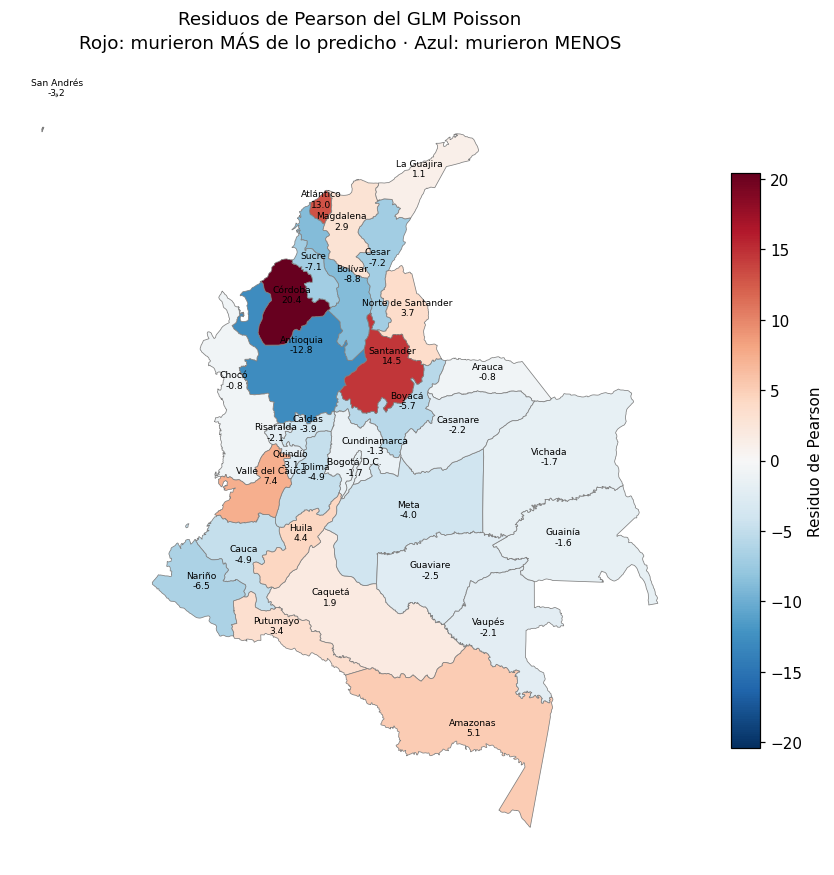

            Estimación  Error est.  IC 95% inf  IC 95% sup  valor p
Intercepto      0.0791      0.0109      0.0578      0.1004   0.0000
HMPI            0.1251      0.0098      0.1058      0.1443   0.0000
EMPI            0.0838      0.0077      0.0686      0.0989   0.0000
WMPI            0.0295      0.0136      0.0029      0.0561   0.0297
DMPI           -0.0726      0.0081     -0.0885     -0.0567   0.0000
YMPI           -0.1570      0.0235     -0.2032     -0.1109   0.0000

Índice de dispersión (χ² de Pearson / g.l.): 54.9


In [9]:
# ==============================================================
# Preparación del modelo y GLM Poisson frecuentista
#   ln(mu_k) = ln(E_k) + x_k' beta      (ln E_k es el offset)
# ==============================================================
y = datos["Y"].values.astype(float)
E = datos["E"].values.astype(float)
offset = np.log(E)

# Las covariables se centran en su media: no cambia las pendientes,
# pero reduce la correlación entre el intercepto y los coeficientes
X_original = datos[covariables].values
X_centrada = X_original - X_original.mean(axis=0)
X = np.column_stack([np.ones(K), X_centrada])      # primera columna = intercepto
p = X.shape[1]
nombres_param = ["Intercepto"] + covariables

# Ajuste del GLM Poisson con offset (método tradicional, para comparar)
glm = sm.GLM(y, X, family=sm.families.Poisson(), offset=offset).fit()
# Mapa de los residuos de Pearson del GLM
datos["residuo_pearson"] = glm.resid_pearson

mapa_res = mapa.merge(datos[["departamento", "residuo_pearson"]], on="departamento")

fig, ax = plt.subplots(figsize=(8, 9))
limite = np.abs(mapa_res["residuo_pearson"]).max()
mapa_res.plot(column="residuo_pearson", cmap="RdBu_r", vmin=-limite, vmax=limite,
              edgecolor="gray", linewidth=0.5, legend=True, ax=ax,
              legend_kwds={"label": "Residuo de Pearson", "shrink": 0.6})

# Escribir el nombre y el residuo de cada departamento
for _, fila in mapa_res.iterrows():
    punto = fila["geometry"].representative_point()
    ax.annotate(f'{fila["departamento"]}\n{fila["residuo_pearson"]:.1f}',
                xy=(punto.x, punto.y), ha="center", fontsize=6)

ax.set_title("Residuos de Pearson del GLM Poisson\nRojo: murieron MÁS de lo predicho · Azul: murieron MENOS")
ax.axis("off")
plt.tight_layout()
plt.savefig("mapa_residuos_glm.pdf")
plt.savefig("mapa_residuos_glm.png", dpi=300)
plt.show()
# Tabla de estimaciones del GLM
tabla_glm = pd.DataFrame({"Estimación": glm.params, "Error est.": glm.bse,
                          "IC 95% inf": glm.conf_int()[:, 0], "IC 95% sup": glm.conf_int()[:, 1],
                          "valor p": glm.pvalues}, index=nombres_param)
print(tabla_glm.round(4))

# Índice de dispersión = chi^2 de Pearson / grados de libertad.
# Bajo el modelo Poisson debería estar cerca de 1; valores mucho mayores indican sobredispersión.
dispersion = np.sum(glm.resid_pearson**2) / glm.df_resid
print("\nÍndice de dispersión (χ² de Pearson / g.l.):", round(dispersion, 1))

**Cómo leer el índice de dispersión:** en un modelo Poisson debería estar cerca de 1, porque la Poisson supone media = varianza. Un valor mucho mayor que 1 indica **sobredispersión**: los datos varían más de lo que el modelo puede explicar. Eso justifica agregar un **efecto aleatorio** por departamento, que es justamente lo que hace el modelo CAR.

## 4. ¿Hay dependencia espacial? Índice de Moran

$$I = \frac{K}{\sum_k\sum_j w_{kj}} \cdot \frac{\sum_k\sum_j w_{kj}(r_k-\bar r)(r_j-\bar r)}{\sum_k (r_k-\bar r)^2}$$

- $I > 0$: los vecinos se parecen. $I < 0$: los vecinos son opuestos. $I \approx 0$: no hay patrón.
- **Prueba por permutaciones:** se reparten los valores al azar entre los departamentos 10 000 veces. Así se ve cómo se comporta $I$ cuando no hay estructura espacial, y se compara con el $I$ real.

Se calcula para el SCFR observado y para los residuos del GLM, que es lo que hace el artículo.

SCFR observado: I = 0.162 | p (autocorr. positiva) = 0.0445 | p (autocorr. negativa) = 0.9555
Residuos de Pearson del GLM: I = -0.258 | p (autocorr. positiva) = 0.9923 | p (autocorr. negativa) = 0.0077


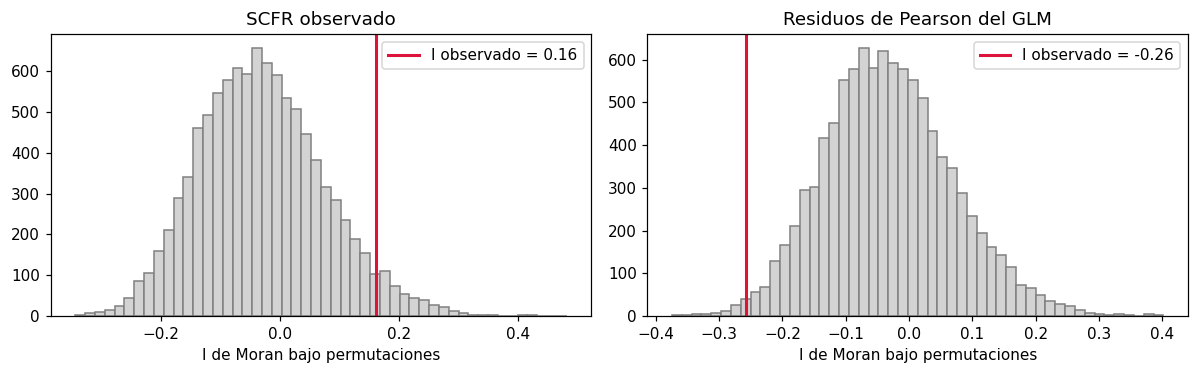

In [10]:
# Índice de Moran: I = K / sum(W) * (r' W r) / (r' r), con r centrado en su media
def indice_moran(r, W):
    r = r - r.mean()
    return len(r) / W.sum() * (r @ W @ r) / (r @ r)

# Prueba por permutaciones: bajo H0 (sin dependencia espacial) los valores son
# intercambiables entre departamentos; se reparten al azar n_perm veces.
def prueba_moran(r, W, n_perm=10000, semilla=123):
    rng = np.random.default_rng(semilla)
    I_obs = indice_moran(r, W)
    I_perm = np.array([indice_moran(rng.permutation(r), W) for _ in range(n_perm)])
    p_pos = np.mean(I_perm >= I_obs)     # H1: autocorrelación positiva
    p_neg = np.mean(I_perm <= I_obs)     # H1: autocorrelación negativa
    return I_obs, I_perm, p_pos, p_neg

# Moran para el SCFR observado y para los residuos del GLM, con su distribución bajo H0
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
for a, (titulo, r) in zip(ax, [("SCFR observado", y / E), ("Residuos de Pearson del GLM", glm.resid_pearson)]):
    I_obs, I_perm, p_pos, p_neg = prueba_moran(r, W)
    print(f"{titulo}: I = {I_obs:.3f} | p (autocorr. positiva) = {p_pos:.4f} | p (autocorr. negativa) = {p_neg:.4f}")
    a.hist(I_perm, bins=50, color="lightgray", edgecolor="gray")
    a.axvline(I_obs, color="crimson", lw=2, label=f"I observado = {I_obs:.2f}")
    a.set_title(titulo); a.set_xlabel("I de Moran bajo permutaciones"); a.legend()
plt.tight_layout(); plt.show()


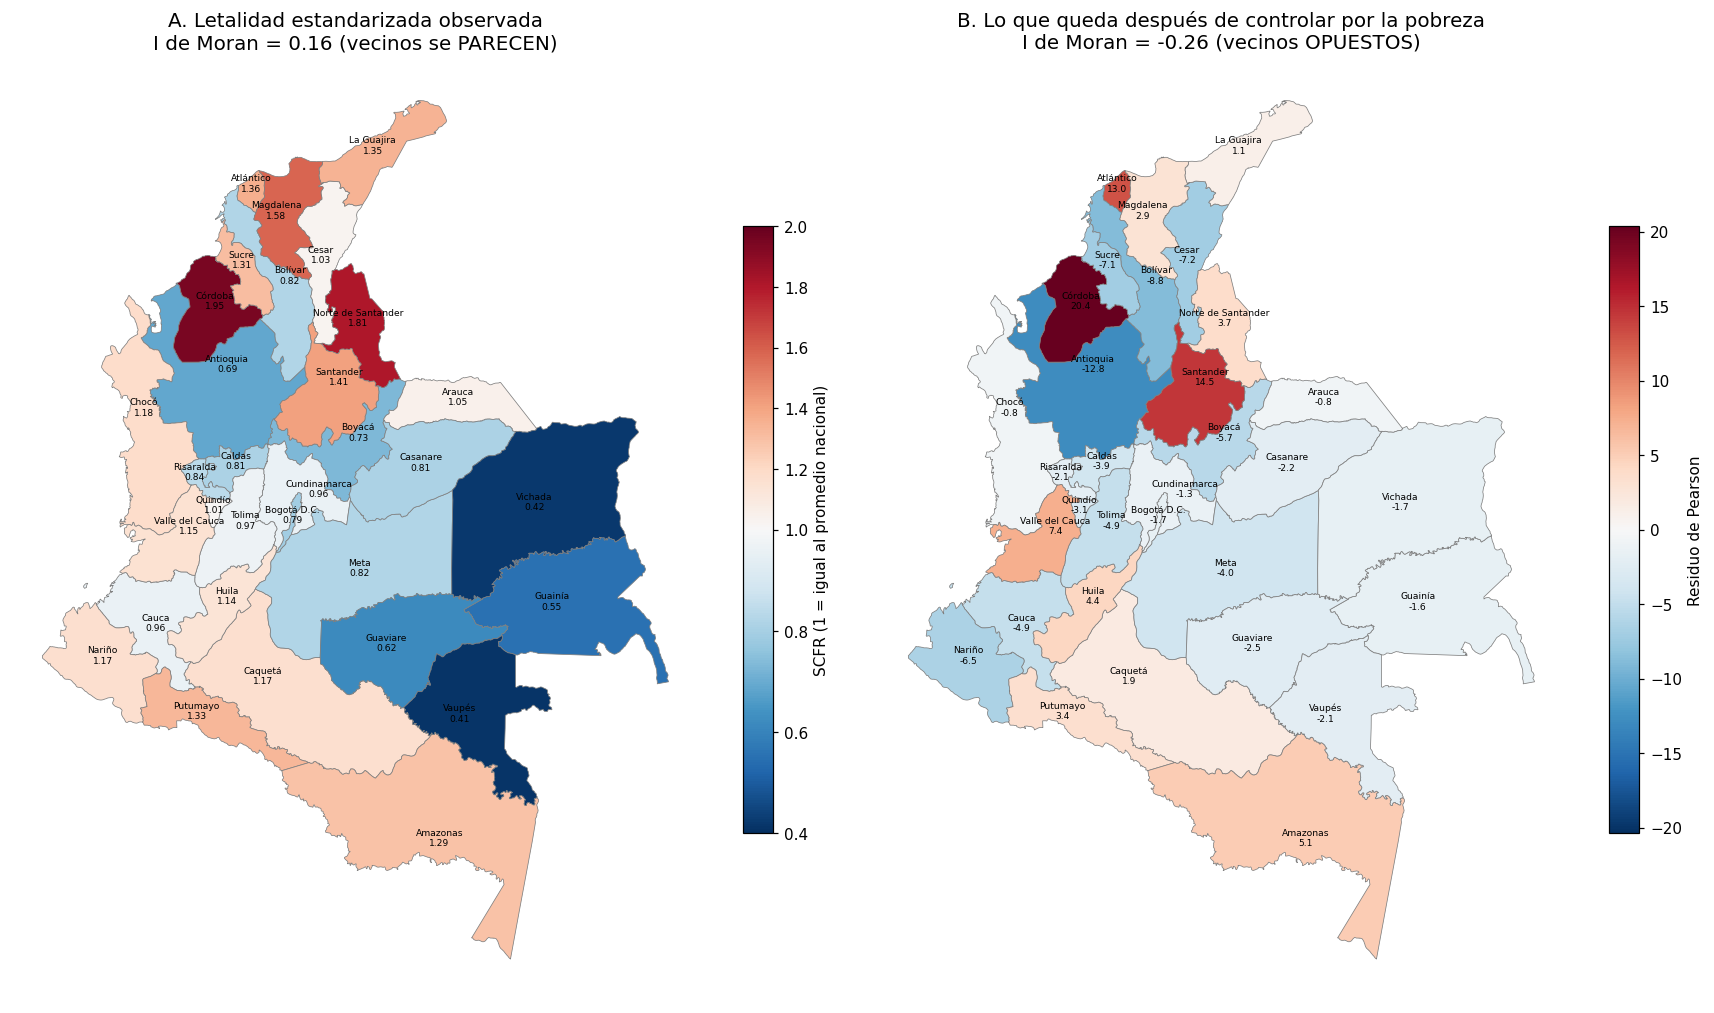

In [11]:
# Figura 1 del informe: mapa del SCFR observado y de los residuos del GLM
from matplotlib.colors import TwoSlopeNorm

# Unir el mapa con el SCFR y los residuos (sin San Andrés, por escala)
datos["residuo_pearson"] = glm.resid_pearson
m2 = mapa.merge(datos[["departamento", "SCFR_calculado", "residuo_pearson"]], on="departamento")
m2 = m2[m2["departamento"] != "San Andrés"]

I_scfr = indice_moran(y / E, W)
I_res = indice_moran(glm.resid_pearson, W)

fig, ax = plt.subplots(1, 2, figsize=(16, 10))

# Mapa A: SCFR observado (centrado en 1 = letalidad nacional)
m2.plot(column="SCFR_calculado", cmap="RdBu_r", norm=TwoSlopeNorm(vmin=0.4, vcenter=1, vmax=2.0),
        edgecolor="gray", linewidth=0.5, legend=True, ax=ax[0],
        legend_kwds={"label": "SCFR (1 = igual al promedio nacional)", "shrink": 0.6})
ax[0].set_title(f"A. Letalidad estandarizada observada\nI de Moran = {I_scfr:.2f} (vecinos se PARECEN)",
                fontsize=13)

# Mapa B: residuos del GLM (centrado en 0)
lim = np.abs(m2["residuo_pearson"]).max()
m2.plot(column="residuo_pearson", cmap="RdBu_r", norm=TwoSlopeNorm(vmin=-lim, vcenter=0, vmax=lim),
        edgecolor="gray", linewidth=0.5, legend=True, ax=ax[1],
        legend_kwds={"label": "Residuo de Pearson", "shrink": 0.6})
ax[1].set_title(f"B. Lo que queda después de controlar por la pobreza\nI de Moran = {I_res:.2f} (vecinos OPUESTOS)",
                fontsize=13)

# Nombres y valores de cada departamento
for a_, col, fmt in [(ax[0], "SCFR_calculado", "{:.2f}"), (ax[1], "residuo_pearson", "{:.1f}")]:
    for _, fila in m2.iterrows():
        pt = fila["geometry"].representative_point()
        a_.annotate(f'{fila["departamento"]}\n{fmt.format(fila[col])}',
                    xy=(pt.x, pt.y), ha="center", fontsize=6)
    a_.axis("off")

plt.tight_layout(rect=[0, 0, 1, 0.95])      # deja espacio arriba para los títulos
plt.savefig("mapa_moran_scfr_residuos.pdf", bbox_inches="tight")
plt.savefig("mapa_moran_scfr_residuos.png", dpi=300, bbox_inches="tight")
plt.show()

> **Comparación con el artículo.** Polo et al. (2022) reportan que los residuos del modelo Poisson presentan autocorrelación espacial **positiva** significativa ($p<0.05$), y con base en eso justifican el uso del modelo CAR. Con los mismos datos (Tablas 1 y 2 del artículo) se obtuvo:
>
> | Variable | I de Moran | Valor p | Interpretación |
> |---|---|---|---|
> | SCFR observado | 0.164 | 0.042 (positiva) | Los departamentos vecinos tienen letalidades parecidas |
> | Residuos del GLM | −0.253 | 0.009 (negativa) | Los vecinos tienen errores de signo **opuesto** |
>
> Es decir, la letalidad sí muestra agrupación espacial, pero **desaparece al controlar por las dimensiones del IPM**, y lo que queda es un patrón de signos opuestos entre vecinos (Córdoba y Santander por encima de lo predicho, rodeados de Antioquia, Bolívar, Sucre y Boyacá por debajo). Esto sugiere que la similitud entre vecinos se explica en buena parte por la distribución espacial de la pobreza, que también está agrupada geográficamente.
>
> **Posibles razones de la diferencia con el artículo:**
> 1. **A qué variable le aplicaron la prueba.** En la ecuación (6) del artículo, $r_k$ se define como "el IPM de cada departamento", aunque en los resultados dicen que la aplicaron a los residuos. Las dimensiones del IPM **sí** tienen autocorrelación positiva fuerte ($I$ entre 0.27 y 0.41), así que es posible que el resultado reportado corresponda a las covariables y no a los residuos.
> 2. **La matriz de vecindad.** El artículo no publica su matriz $W$; si definieron los vecinos de otra forma (por ejemplo, por distancia), el índice puede cambiar.
> 3. **El tipo de residuo.** El artículo no dice qué residuos usó (de Pearson, de devianza u otros).
>
> En cualquier caso, el modelo CAR de Leroux sigue siendo adecuado, porque el parámetro $\rho$ se estima a partir de los datos: si la dependencia espacial es débil, $\rho$ toma valores cercanos a 0 y el modelo se comporta como uno de efectos aleatorios independientes.

## 5 y 6. Modelos bayesianos

Se programa **una sola función** que ajusta los dos modelos:

- `espacial=False`: Poisson bayesiano **sin** efecto espacial. Solo hay que muestrear $\boldsymbol\beta$.
- `espacial=True`: modelo **CAR de Leroux**. Se agregan $\phi_1,\dots,\phi_{33}$, $\tau^2$ y $\rho$.

**Prioris** (las mismas del artículo y del paquete CARBayes):

$$\boldsymbol\beta \sim N(\mathbf 0,\ 100\,000\, I), \qquad \tau^2 \sim \text{Inv-Gamma}(a=1,\ b=0.01), \qquad \rho \sim \text{Uniforme}(0,1)$$

$$\phi_k \mid \boldsymbol\phi_{-k} \sim N\!\left(\frac{\rho\sum_i w_{ki}\phi_i}{\rho\, n_k + 1-\rho},\ \frac{\tau^2}{\rho\, n_k+1-\rho}\right)$$

**Algoritmo: Metropolis dentro de Gibbs** (clases 5 y 6). En cada iteración:

| Parámetro | Condicional completa | Cómo se muestrea |
|---|---|---|
| $\boldsymbol\beta$ | Poisson × Normal: forma no conocida | **Metropolis–Hastings** (todo el vector a la vez) |
| $\phi_k$ | Poisson × Normal condicional: forma no conocida | **Metropolis–Hastings**, uno por uno |
| $\tau^2$ | $\text{Inv-Gamma}\big(a+\tfrac K2,\ b+\tfrac12\boldsymbol\phi^\top Q(\rho)\boldsymbol\phi\big)$ | **Gibbs** (forma conocida) |
| $\rho$ | $\propto \lvert Q(\rho)\rvert^{1/2}\exp\!\big(-\boldsymbol\phi^\top Q(\rho)\boldsymbol\phi/2\tau^2\big)$ en $(0,1)$ | **Metropolis–Hastings** |

con $Q(\rho) = \rho\,(D_W - W) + (1-\rho)\,I$.

**Detalles del código:**
- En Metropolis se trabaja con **logaritmos**: se acepta si $\log u < \log \alpha$. Es lo mismo que $u<\alpha$, pero evita números demasiado pequeños.
- La propuesta de $\boldsymbol\beta$ empieza con la forma de la matriz de covarianza del GLM y, durante el burn-in, se reemplaza por la covarianza de las muestras de $\boldsymbol\beta$. Así los pasos siguen la forma real de la posterior (las dimensiones del IPM están muy correlacionadas entre sí).
- Después de actualizar los $\phi_k$ se **centran** (se les resta su media y esa media pasa al intercepto). Esto no cambia el modelo para los riesgos, pero evita que el intercepto y los $\phi$ se "peleen" la media, que impide la convergencia.
- Durante el **burn-in** el tamaño de los pasos se ajusta solo, para que la tasa de aceptación quede en un rango razonable (entre 20 % y 50 %). Después del burn-in queda fijo.
- $\log\lvert Q(\rho)\rvert = \sum_i \log(\rho\lambda_i + 1-\rho)$, donde $\lambda_i$ son los valores propios de $D_W - W$. Así no hay que calcular un determinante en cada iteración.

In [12]:
# ==============================================================
# MUESTREADOR: Metropolis dentro de Gibbs para el modelo CAR de Leroux
#   Y_k | beta, phi_k ~ Poisson(E_k exp(x_k' beta + phi_k))
#   phi | tau2, rho  ~ N(0, tau2 Q(rho)^-1),  Q(rho) = rho (D_W - W) + (1 - rho) I
#   beta ~ N(0, var_beta I),  tau2 ~ Inv-Gamma(a, b),  rho ~ U(0, 1)
# En cada iteración se actualiza:
#   1) beta    -> Metropolis (vector completo)
#   2) phi_k   -> Metropolis (uno por uno, usando la condicional CAR)
#   3) tau2    -> Gibbs (condicional completa Inversa-Gamma)
#   4) rho     -> Metropolis en (0, 1)
# Con espacial=False se omiten phi, tau2 y rho (Poisson bayesiano sin espacio).
# ==============================================================
import math
import time

# Cantidades fijas que se calculan una sola vez antes de las cadenas
D_W = np.diag(n_vecinos)
L_W = D_W - W                                # matriz D_W - W (se usa en Q(rho))
lambdas = np.linalg.eigvalsh(L_W)            # valores propios de D_W - W (se calculan una vez)
lista_vecinos = [list(np.nonzero(W[k])[0]) for k in range(K)]   # vecinos de cada departamento
cov_propuesta = glm.cov_params()             # forma inicial de la propuesta para beta
L_prop = np.linalg.cholesky(cov_propuesta)

def log_verosimilitud(eta):
    # log p(y | mu) de la Poisson, con mu = exp(eta)
    return np.sum(y * eta - np.exp(eta) - gammaln(y + 1))

def forma_cuadratica(phi, r):
    # phi' Q(r) phi  con  Q(r) = r (D_W - W) + (1 - r) I
    return r * (phi @ L_W @ phi) + (1 - r) * (phi @ phi)

def log_post_rho(r, phi, tau2):
    # log p(rho | resto) = 0.5 log|Q(rho)| - phi'Q(rho)phi / (2 tau2)   (priori uniforme: constante)
    return 0.5 * np.sum(np.log(np.maximum(r * lambdas + 1 - r, 1e-12))) - forma_cuadratica(phi, r) / (2 * tau2)

# Ajusta UNA cadena. Parámetros: a, b = priori de tau2; var_beta = varianza de la priori de beta;
# n_iter = iteraciones totales; burn_in = iteraciones descartadas; thin = se guarda 1 de cada 'thin'.
def ajustar_modelo(espacial=True, a=1.0, b=0.01, var_beta=1e5,
                   n_iter=300000, burn_in=50000, thin=250, semilla=0):
    rng = np.random.default_rng(semilla)

    # ---- Valores iniciales (distintos en cada cadena) ----
    beta = glm.params + rng.normal(0, 0.2, p)
    phi = rng.normal(0, 0.1, K) if espacial else np.zeros(K)
    tau2 = rng.uniform(0.05, 0.5)
    rho = rng.uniform(0.1, 0.9)

    # ---- Tamaños de paso iniciales (se ajustan en el burn-in) ----
    paso_beta, paso_phi, paso_rho = 0.5, np.full(K, 0.1), 0.1
    L_beta = L_prop.copy()          # forma inicial de la propuesta: la covarianza del GLM
    historial_beta = []
    acept_beta, acept_phi, acept_rho = 0, np.zeros(K), 0
    y_lista = y.tolist()

    guardado = {"beta": [], "phi": [], "tau2": [], "rho": [], "mu": [], "loglik": []}
    log_post_beta = lambda bt, ph: log_verosimilitud(offset + X @ bt + ph) - bt @ bt / (2 * var_beta)

    for it in range(n_iter):
        # 1) beta | resto  ->  Metropolis-Hastings (todo el vector a la vez)
        beta_prop = beta + paso_beta * (L_beta @ rng.normal(size=p))
        log_alpha = log_post_beta(beta_prop, phi) - log_post_beta(beta, phi)
        if np.log(rng.uniform()) < log_alpha:
            beta = beta_prop
            acept_beta += 1

        if espacial:
            # 2) phi_k | resto  ->  Metropolis-Hastings, uno por uno
            #    (se usan listas de Python y math.exp porque son mucho más rápidas para números sueltos)
            eta_sin_phi = (offset + X @ beta).tolist()
            ph = phi.tolist()
            z = rng.normal(size=K).tolist()
            log_u = np.log(rng.uniform(size=K)).tolist()
            pasos = paso_phi.tolist()
            for k in range(K):
                denom = rho * n_vecinos[k] + 1 - rho
                media_k = rho * sum(ph[j] for j in lista_vecinos[k]) / denom   # media condicional CAR
                precision_k = denom / tau2                                     # 1 / varianza condicional
                viejo = ph[k]
                nuevo = viejo + pasos[k] * z[k]
                log_alpha = (y_lista[k] * nuevo - math.exp(eta_sin_phi[k] + nuevo)) \
                          - (y_lista[k] * viejo - math.exp(eta_sin_phi[k] + viejo)) \
                          - 0.5 * precision_k * ((nuevo - media_k) ** 2 - (viejo - media_k) ** 2)
                if log_u[k] < log_alpha:
                    ph[k] = nuevo
                    acept_phi[k] += 1
            phi = np.array(ph)

            # Centrar phi: sumar una constante a todos los phi y restarla del intercepto no cambia
            # la verosimilitud, así que se deja la media de phi en el intercepto (lo mismo hace CARBayes).
            # Sin esto, el intercepto y los phi "se roban" la media y la cadena no converge.
            centro = phi.mean()
            phi -= centro
            beta[0] += centro

            # 3) tau2 | resto  ->  Gibbs: Inversa-Gamma(a + K/2, b + phi'Q phi / 2)
            forma = a + K / 2
            escala = b + 0.5 * forma_cuadratica(phi, rho)
            tau2 = 1 / rng.gamma(forma, 1 / escala)

            # 4) rho | resto  ->  Metropolis-Hastings en (0, 1)
            rho_prop = rho + paso_rho * rng.normal()
            if 0 < rho_prop < 1:                          # fuera de (0,1) la priori vale 0: se rechaza
                if np.log(rng.uniform()) < log_post_rho(rho_prop, phi, tau2) - log_post_rho(rho, phi, tau2):
                    rho = rho_prop
                    acept_rho += 1

        # ---- Durante el burn-in se aprende la forma de la propuesta de beta ----
        # (covarianza de las muestras de beta: así los pasos siguen la forma real de la posterior)
        if it < burn_in:
            historial_beta.append(beta.copy())
            if it + 1 in (burn_in // 2, (3 * burn_in) // 4):
                L_beta = np.linalg.cholesky(np.cov(np.array(historial_beta[len(historial_beta) // 3:]).T) + 1e-8 * np.eye(p))
                paso_beta = 2.38 / np.sqrt(p)

        # ---- Ajuste automático del tamaño de paso (solo durante el burn-in) ----
        if it < burn_in and (it + 1) % 200 == 0:
            paso_beta *= np.exp(acept_beta / 200 - 0.30); acept_beta = 0
            paso_phi *= np.exp(acept_phi / 200 - 0.40); acept_phi[:] = 0
            paso_rho *= np.exp(acept_rho / 200 - 0.40); acept_rho = 0
        if it == burn_in:
            acept_beta, acept_phi[:], acept_rho = 0, 0, 0

        # ---- Guardar (después del burn-in, una de cada 'thin') ----
        if it >= burn_in and (it - burn_in) % thin == 0:
            eta = offset + X @ beta + phi
            guardado["beta"].append(beta.copy()); guardado["phi"].append(phi.copy())
            guardado["tau2"].append(tau2); guardado["rho"].append(rho)
            guardado["mu"].append(np.exp(eta)); guardado["loglik"].append(log_verosimilitud(eta))

    n_post = n_iter - burn_in
    tasas = {"beta": round(acept_beta / n_post, 2)}
    if espacial:
        tasas.update({"phi (promedio)": round(float(acept_phi.mean()) / n_post, 2), "rho": round(acept_rho / n_post, 2)})
    resultado = {k: np.array(v) for k, v in guardado.items()}
    resultado["tasas"] = tasas
    return resultado

# Corre varias cadenas con semillas distintas (100, 101, 102) para evaluar convergencia
def correr_cadenas(n_cadenas=3, **kwargs):
    cadenas = []
    for c in range(n_cadenas):
        inicio = time.time()
        r = ajustar_modelo(semilla=100 + c, **kwargs)
        print(f"  Cadena {c + 1}: tasas de aceptación {r['tasas']}  ({time.time() - inicio:.0f} s)")
        cadenas.append(r)
    return cadenas

### 5. Poisson bayesiano sin efecto espacial

   3 cadenas de 300 000 iteraciones: se descartan las primeras 50 000 (burn-in) y se guarda una de cada 250 (thinning). Quedan 1 000 muestras por cadena.

In [13]:
# Modelo bayesiano SIN efectos espaciales (comparación con el GLM y con el CAR)
print("Poisson bayesiano sin efecto espacial")
cadenas_poisson = correr_cadenas(espacial=False)

Poisson bayesiano sin efecto espacial
  Cadena 1: tasas de aceptación {'beta': 0.33}  (13 s)
  Cadena 2: tasas de aceptación {'beta': 0.31}  (12 s)
  Cadena 3: tasas de aceptación {'beta': 0.29}  (12 s)


### 6. Modelo CAR de Leroux

Misma configuración: 3 cadenas × 300 000 iteraciones, burn-in 50 000, thinning 250 (1 000 muestras por cadena). El artículo usó 2 200 000 iteraciones por cadena con thinning de 1 000; aquí se usan menos porque el ajuste automático del paso hace que las cadenas mezclen bien con menos iteraciones. La convergencia se comprueba en el paso 7.

In [14]:
# Modelo principal: CAR de Leroux con la priori del artículo, tau2 ~ Inv-Gamma(1, 0.01)
print("Modelo CAR de Leroux, priori tau2 ~ Inv-Gamma(1, 0.01)")
cadenas_car = correr_cadenas(espacial=True, a=1.0, b=0.01)

Modelo CAR de Leroux, priori tau2 ~ Inv-Gamma(1, 0.01)
  Cadena 1: tasas de aceptación {'beta': 0.3, 'phi (promedio)': 0.4, 'rho': 0.35}  (64 s)
  Cadena 2: tasas de aceptación {'beta': 0.3, 'phi (promedio)': 0.4, 'rho': 0.38}  (74 s)
  Cadena 3: tasas de aceptación {'beta': 0.33, 'phi (promedio)': 0.4, 'rho': 0.46}  (78 s)


## 7. Convergencia

Cuatro herramientas:

| Herramienta | Qué mira | Criterio |
|---|---|---|
| **Gráfico de traza** | Que las 3 cadenas se mezclen y recorran la misma zona | Deben verse como "ruido" sin tendencia y encimadas |
| **$\hat R$ de Gelman–Rubin** | Compara la varianza **entre** cadenas con la varianza **dentro** de cada cadena | $\hat R < 1.1$ |
| **Tamaño de muestra efectivo** | Cuántas muestras independientes "valen" las muestras correlacionadas | Mientras más grande, mejor (al menos unas 100) |
| **Geweke** | Compara la media del primer 10 % de la cadena con la del último 50 % | Entre $-2$ y $2$ |

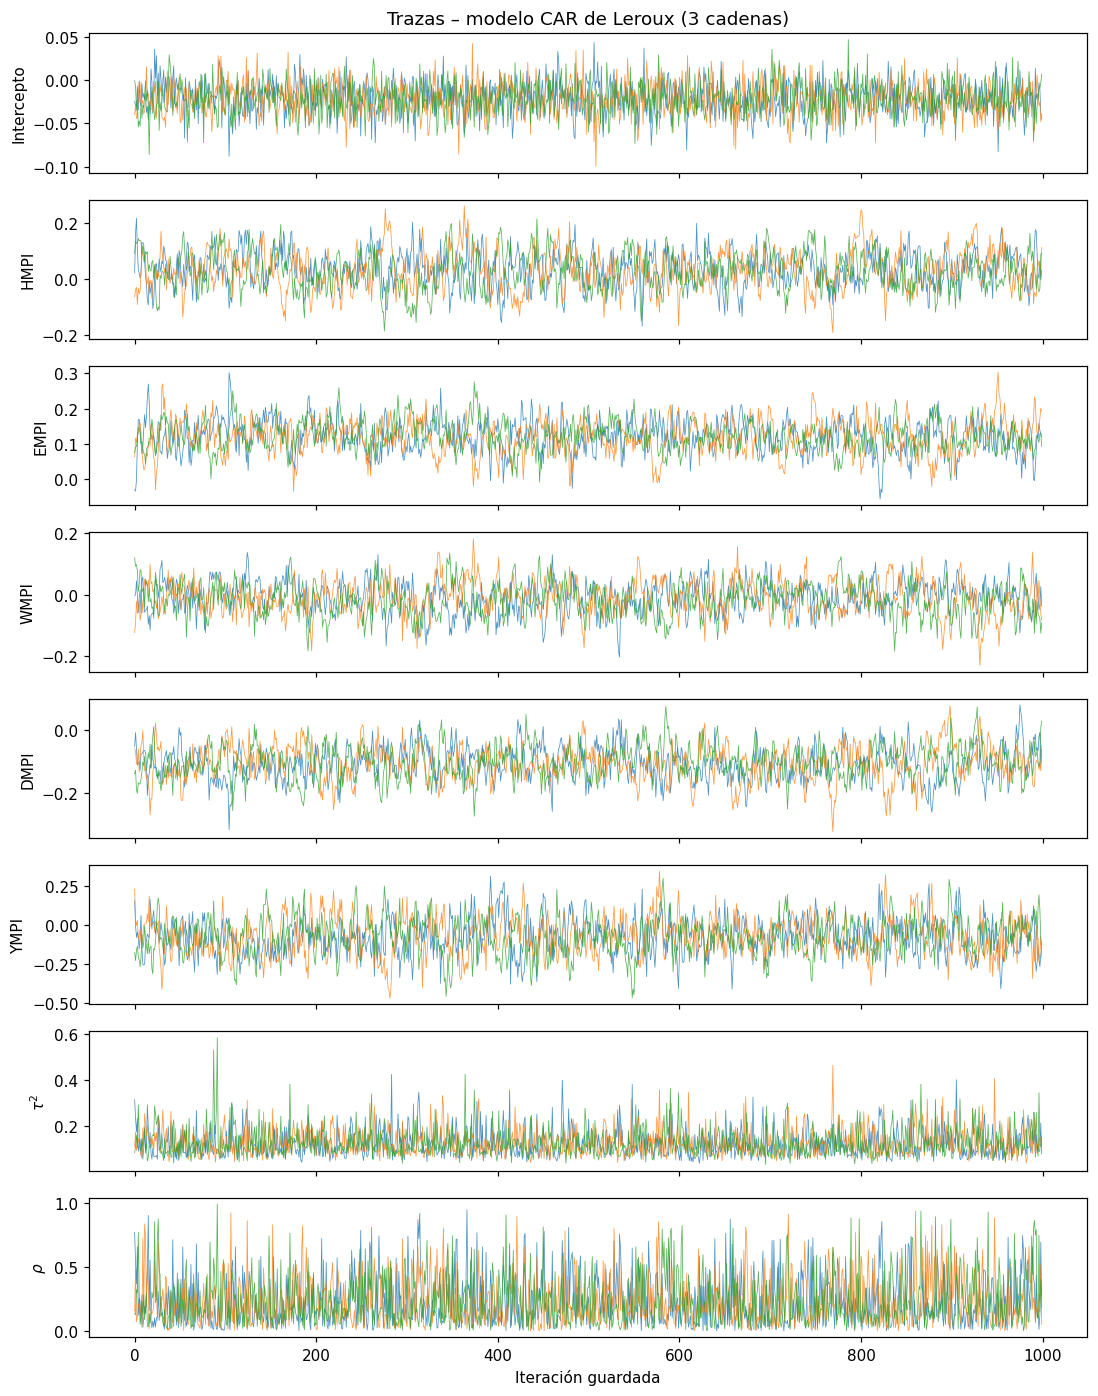

In [15]:
# ---------------- Diagnósticos de convergencia ----------------
def juntar(cadenas, nombre, j=None):
    # devuelve una matriz (n_cadenas x n_muestras) para un parámetro
    if j is None:
        return np.array([c[nombre] for c in cadenas])
    return np.array([c[nombre][:, j] for c in cadenas])

# R-hat de Gelman-Rubin: compara la varianza entre cadenas (B) con la varianza dentro (Wd).
# Valores < 1.1 indican que las cadenas llegaron a la misma distribución.
def r_hat(m):
    n = m.shape[1]
    B = n * m.mean(axis=1).var(ddof=1)
    Wd = m.var(axis=1, ddof=1).mean()
    return np.sqrt(((n - 1) / n * Wd + B / n) / Wd)

# Tamaño de muestra efectivo: n / (1 + 2 * suma de autocorrelaciones).
# La suma se corta cuando la autocorrelación baja de 0.05.
def tamano_efectivo(m):
    total = 0
    for x in m:
        x = x - x.mean(); n = len(x)
        acf = np.correlate(x, x, mode="full")[n - 1:] / (x @ x)
        suma = 0
        for t in range(1, n):
            if acf[t] < 0.05: break
            suma += acf[t]
        total += n / (1 + 2 * suma)
    return total

# Diagnóstico de Geweke: compara la media del primer 10 % con la del último 50 % de la cadena.
# |z| < 2 indica que la cadena es estacionaria.
def geweke(x, primero=0.1, ultimo=0.5):
    a = x[: int(primero * len(x))]; b = x[int((1 - ultimo) * len(x)):]
    def var_media(z):                         # varianza de la media con medias por lotes (corrige autocorrelación)
        lotes = np.array_split(z, 10)
        return np.var([l.mean() for l in lotes], ddof=1) / 10
    return (a.mean() - b.mean()) / np.sqrt(var_media(a) + var_media(b))

# Resumen posterior: media, mediana, IC 95 % y diagnósticos de cada parámetro
def tabla_posterior(cadenas, espacial=True):
    filas = {}
    params = [(nombres_param[j], "beta", j) for j in range(p)]
    if espacial:
        params += [("tau2", "tau2", None), ("rho", "rho", None)]
    for nombre, clave, j in params:
        m = juntar(cadenas, clave, j)
        todas = m.ravel()
        filas[nombre] = {"Media": todas.mean(), "Mediana": np.median(todas),
                         "2.5%": np.quantile(todas, 0.025), "97.5%": np.quantile(todas, 0.975),
                         "R-hat": r_hat(m), "n efectivo": tamano_efectivo(m),
                         "Geweke": geweke(m[0])}
    return pd.DataFrame(filas).T

# Gráfico de trazas: las tres cadenas deben mezclarse y oscilar alrededor del mismo valor
def graficar_trazas(cadenas, espacial=True, titulo=""):
    params = [(nombres_param[j], "beta", j) for j in range(p)]
    if espacial:
        params += [(r"$\tau^2$", "tau2", None), (r"$\rho$", "rho", None)]
    fig, ax = plt.subplots(len(params), 1, figsize=(10, 1.6 * len(params)), sharex=True)
    for a_, (nombre, clave, j) in zip(ax, params):
        for c, color in zip(juntar(cadenas, clave, j), ["tab:blue", "tab:orange", "tab:green"]):
            a_.plot(c, lw=0.5, color=color, alpha=0.8)
        a_.set_ylabel(nombre)
    ax[0].set_title(titulo); ax[-1].set_xlabel("Iteración guardada")
    plt.tight_layout(); plt.show()

graficar_trazas(cadenas_car, titulo="Trazas – modelo CAR de Leroux (3 cadenas)")

## 8. Resultados

### Tabla posterior del modelo CAR (equivalente a la Tabla 3 del artículo)

Recuerda: los coeficientes son de las covariables **centradas**. Las pendientes se interpretan igual que en el artículo; solo cambia el intercepto.

In [16]:
# Tabla 1 del informe: resumen posterior del modelo CAR
post_car = tabla_posterior(cadenas_car)
post_car.round(3)

,Media,Mediana,2.5%,97.5%,R-hat,n efectivo,Geweke
Intercepto,-0.021,-0.021,-0.058,0.016,1.000,2151.798,2.996
HMPI,0.032,0.030,-0.099,0.164,1.001,512.862,0.122
EMPI,0.121,0.122,0.031,0.209,1.000,494.500,0.472
WMPI,-0.012,-0.011,-0.122,0.088,1.002,533.186,0.596
DMPI,-0.105,-0.105,-0.209,0.004,1.002,526.575,0.031
YMPI,-0.075,-0.078,-0.306,0.167,1.000,622.900,-0.093
tau2,0.128,0.115,0.054,0.274,1.001,1987.929,-0.841
rho,0.234,0.183,0.008,0.730,1.000,2036.435,-1.235


**Comparación con la Tabla 3 del artículo:**

In [17]:
# Comparación con la Tabla 3 de Polo et al. (2022)
articulo_tabla3 = pd.DataFrame({
    "Mediana (artículo)": [0.142, 0.056, -0.055, 0.636, 0.060, 0.612],
    "2.5% (artículo)": [0.015, 0.011, -0.183, 0.228, 0.037, 0.219],
    "97.5% (artículo)": [0.214, 0.215, 0.097, 0.901, 0.534, 0.782]},
    index=["HMPI", "EMPI", "WMPI", "DMPI", "YMPI", "rho"])
comparacion = post_car.loc[articulo_tabla3.index, ["Mediana", "2.5%", "97.5%"]].join(articulo_tabla3)
comparacion.round(3)

,Mediana,2.5%,97.5%,Mediana (artículo),2.5% (artículo),97.5% (artículo)
HMPI,0.030,-0.099,0.164,0.142,0.015,0.214
EMPI,0.122,0.031,0.209,0.056,0.011,0.215
WMPI,-0.011,-0.122,0.088,-0.055,-0.183,0.097
DMPI,-0.105,-0.209,0.004,0.636,0.228,0.901
YMPI,-0.078,-0.306,0.167,0.060,0.037,0.534
rho,0.183,0.008,0.730,0.612,0.219,0.782


### Riesgos relativos (equivalente a la Tabla 4 del artículo)

$$RR_j = \exp(\beta_j\,\xi_j), \qquad \xi_j = \text{desviación estándar de la covariable } j$$

Se calcula con **cada muestra** de $\beta_j$ (Monte Carlo) y luego se resume con la mediana y el intervalo de credibilidad del 95 %. Si el intervalo **contiene el 1**, no hay evidencia de efecto.

In [18]:
# Riesgos relativos: RR_j = exp(beta_j * xi_j), con xi_j = desviación estándar de la covariable j.
# Se calcula para cada muestra MCMC, así se obtiene su distribución posterior completa.
desv_est = X_original.std(axis=0, ddof=1)
articulo_rr = {"HMPI": (1.16, 1.06, 2.04), "EMPI": (1.69, 1.36, 5.94), "WMPI": (1.02, 0.80, 3.06),
               "DMPI": (1.74, 1.54, 9.75), "YMPI": (1.35, 1.08, 4.03)}

# Tabla 2 del informe: RR posterior, IC 95 %, P(RR > 1) y valor del artículo
def tabla_rr(cadenas):
    filas = {}
    for j, cov in enumerate(covariables):
        beta_j = juntar(cadenas, "beta", j + 1).ravel()
        rr = np.exp(beta_j * desv_est[j])
        filas[f"{cov} ({nombres_cov[cov]})"] = {
            "xi (desv. est.)": desv_est[j], "RR mediana": np.median(rr),
            "2.5%": np.quantile(rr, 0.025), "97.5%": np.quantile(rr, 0.975),
            "P(RR > 1)": np.mean(rr > 1),
            "RR artículo": articulo_rr[cov][0],
            "IC artículo": f"({articulo_rr[cov][1]}, {articulo_rr[cov][2]})"}
    return pd.DataFrame(filas).T

rr_car = tabla_rr(cadenas_car)
rr_car

,xi (desv. est.),RR mediana,2.5%,97.5%,P(RR > 1),RR artículo,IC artículo
HMPI (Salud),1.630329,1.049917,0.851393,1.305698,0.682667,1.16,"(1.06, 2.04)"
EMPI (Educación),4.241826,1.676453,1.142159,2.427774,0.991667,1.69,"(1.36, 5.94)"
WMPI (Trabajo),4.523512,0.95085,0.575554,1.486136,0.413667,1.02,"(0.8, 3.06)"
DMPI (Vivienda),4.066488,0.653307,0.427962,1.015818,0.028333,1.74,"(1.54, 9.75)"
YMPI (Niñez y juventud),1.780449,0.87064,0.579944,1.346423,0.267667,1.35,"(1.08, 4.03)"


**$P(RR>1)$** es la probabilidad posterior de que esa dimensión **aumente** el riesgo. Es una ventaja del enfoque bayesiano: se puede responder directamente "¿qué tan probable es que la vivienda aumente el riesgo?", cosa que un valor $p$ no dice.

## 9. Comparación de modelos y sensibilidad a la priori

### DIC

$$\text{DIC} = \bar D + p_D, \qquad \bar D = \text{media de } -2\log p(\mathbf y\mid\boldsymbol\theta^{(s)}), \qquad p_D = \bar D - D(\hat{\boldsymbol\mu})$$

$p_D$ es el **número efectivo de parámetros**. Menor DIC = mejor balance entre ajuste y complejidad.

In [19]:
# DIC = D_barra + pD, con D = -2 log verosimilitud.
#   D_barra = media posterior de la devianza; pD = D_barra - D(media posterior de mu).
def dic(cadenas):
    loglik = np.concatenate([c["loglik"] for c in cadenas])
    mu = np.concatenate([c["mu"] for c in cadenas])
    D_barra = np.mean(-2 * loglik)
    D_en_media = -2 * log_verosimilitud(np.log(mu.mean(axis=0)))
    pD = D_barra - D_en_media
    return D_barra + pD, pD

dic_poisson, pd_poisson = dic(cadenas_poisson)
dic_car, pd_car = dic(cadenas_car)
print(f"Poisson bayesiano sin espacio: DIC = {dic_poisson:.1f}, pD = {pd_poisson:.1f}")
print(f"CAR de Leroux:                 DIC = {dic_car:.1f}, pD = {pd_car:.1f}")
print("(DIC del artículo para el CAR: 320.79)")

Poisson bayesiano sin espacio: DIC = 1677.1, pD = 5.8
CAR de Leroux:                 DIC = 312.7, pD = 30.3
(DIC del artículo para el CAR: 320.79)


### Sensibilidad a la priori de $\tau^2$

Se repite el modelo CAR cambiando **solo** la priori de $\tau^2$:

| Priori | Idea |
|---|---|
| Inv-Gamma(1, 0.01) | La del artículo |
| Inv-Gamma(0.001, 0.001) | Muy vaga, muy usada en epidemiología espacial |
| Inv-Gamma(1, 1) | Más informativa: favorece valores más grandes de $\tau^2$ |

Si las conclusiones no cambian, los resultados son **robustos** a la priori.

In [22]:
# Sensibilidad a la priori de tau2: se repite el modelo CAR con dos prioris distintas
print("CAR con tau2 ~ Inv-Gamma(0.001, 0.001)")
cadenas_vaga = correr_cadenas(espacial=True, a=0.001, b=0.001)
print("CAR con tau2 ~ Inv-Gamma(1, 1)")
cadenas_inf = correr_cadenas(espacial=True, a=1.0, b=1.0)

CAR con tau2 ~ Inv-Gamma(0.001, 0.001)
  Cadena 1: tasas de aceptación {'beta': 0.29, 'phi (promedio)': 0.4, 'rho': 0.42}  (70 s)
  Cadena 2: tasas de aceptación {'beta': 0.27, 'phi (promedio)': 0.4, 'rho': 0.45}  (75 s)
  Cadena 3: tasas de aceptación {'beta': 0.3, 'phi (promedio)': 0.4, 'rho': 0.45}  (71 s)
CAR con tau2 ~ Inv-Gamma(1, 1)
  Cadena 1: tasas de aceptación {'beta': 0.29, 'phi (promedio)': 0.4, 'rho': 0.42}  (73 s)
  Cadena 2: tasas de aceptación {'beta': 0.3, 'phi (promedio)': 0.4, 'rho': 0.38}  (80 s)
  Cadena 3: tasas de aceptación {'beta': 0.32, 'phi (promedio)': 0.4, 'rho': 0.42}  (73 s)


In [23]:
# Tabla 3 del informe: comparación de modelos (GLM, Poisson bayesiano, CAR con 3 prioris)
modelos = {"GLM Poisson frecuentista": None,
           "Poisson bayesiano sin espacio": cadenas_poisson,
           "CAR Leroux, IG(1, 0.01)": cadenas_car,
           "CAR Leroux, IG(0.001, 0.001)": cadenas_vaga,
           "CAR Leroux, IG(1, 1)": cadenas_inf}

filas = {}
for nombre, cad in modelos.items():
    fila = {}
    for j, cov in enumerate(covariables):
        if cad is None:
            b = glm.params[j + 1]; lo, hi = glm.conf_int()[j + 1]
        else:
            m = juntar(cad, "beta", j + 1).ravel()
            b, lo, hi = np.median(m), np.quantile(m, 0.025), np.quantile(m, 0.975)
        fila[cov] = f"{b:.3f} ({lo:.3f}, {hi:.3f})"
    if cad is None:
        fila["DIC"], fila["rho"] = "—", "—"
    else:
        fila["DIC"] = f"{dic(cad)[0]:.1f}"
        fila["rho"] = f"{np.median(juntar(cad, 'rho')):.2f}" if "CAR" in nombre else "—"
    filas[nombre] = fila
comparacion_modelos = pd.DataFrame(filas).T
comparacion_modelos

,HMPI,EMPI,WMPI,DMPI,YMPI,DIC,rho
GLM Poisson frecuentista,"0.125 (0.106, 0.144)","0.084 (0.069, 0.099)","0.029 (0.003, 0.056)","-0.073 (-0.088, -0.057)","-0.157 (-0.203, -0.111)",—,—
Poisson bayesiano sin espacio,"0.125 (0.107, 0.144)","0.084 (0.069, 0.099)","0.030 (0.001, 0.056)","-0.072 (-0.089, -0.057)","-0.157 (-0.203, -0.113)",1677.1,—
"CAR Leroux, IG(1, 0.01)","0.030 (-0.099, 0.164)","0.122 (0.031, 0.209)","-0.011 (-0.122, 0.088)","-0.105 (-0.209, 0.004)","-0.078 (-0.306, 0.167)",312.7,0.18
"CAR Leroux, IG(0.001, 0.001)","0.037 (-0.103, 0.184)","0.120 (0.017, 0.214)","-0.016 (-0.126, 0.093)","-0.097 (-0.205, 0.008)","-0.082 (-0.347, 0.179)",312.5,0.25
"CAR Leroux, IG(1, 1)","0.029 (-0.137, 0.194)","0.111 (-0.013, 0.234)","-0.016 (-0.148, 0.123)","-0.102 (-0.244, 0.032)","-0.045 (-0.357, 0.244)",312.7,0.49


Cada celda es **estimación (intervalo del 95 %)** del coeficiente. En el GLM el intervalo es de confianza; en los modelos bayesianos, de credibilidad.

**Qué mirar:** ¿cambian los signos? ¿Algún intervalo que no contenía el 0 pasa a contenerlo? ¿Cambia mucho $\rho$?

## 10. Gráficos para el informe

### Distribuciones posteriores de los coeficientes y de $\rho$

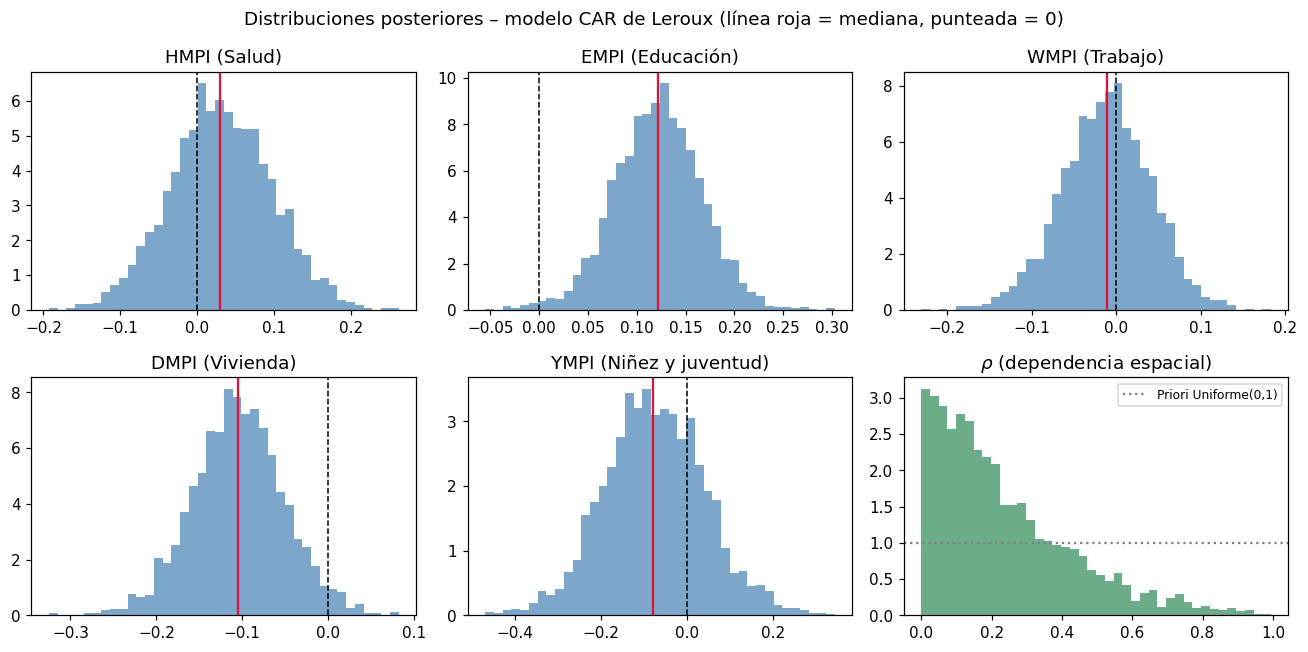

In [24]:
# Figura 2 del informe: distribuciones posteriores de los coeficientes y de rho
fig, ax = plt.subplots(2, 3, figsize=(12, 6))
for a_, j in zip(ax.ravel()[:5], range(5)):
    m = juntar(cadenas_car, "beta", j + 1).ravel()
    a_.hist(m, bins=40, density=True, color="steelblue", alpha=0.7)
    a_.axvline(0, color="black", ls="--", lw=1)
    a_.axvline(np.median(m), color="crimson", lw=1.5)
    a_.set_title(f"{covariables[j]} ({nombres_cov[covariables[j]]})")
m = juntar(cadenas_car, "rho").ravel()
ax[1, 2].hist(m, bins=40, density=True, color="seagreen", alpha=0.7)
ax[1, 2].axhline(1, color="gray", ls=":", label="Priori Uniforme(0,1)")
ax[1, 2].set_title(r"$\rho$ (dependencia espacial)"); ax[1, 2].legend(fontsize=8)
plt.suptitle("Distribuciones posteriores – modelo CAR de Leroux (línea roja = mediana, punteada = 0)")
plt.tight_layout(); plt.savefig("posteriores.pdf"); plt.show()

### Riesgo relativo estimado por departamento

$$\hat R_k = \text{mediana posterior de } \mu_k / E_k$$

Es la versión "suavizada" del SCFR: combina los datos del departamento, sus covariables y la información de sus vecinos.

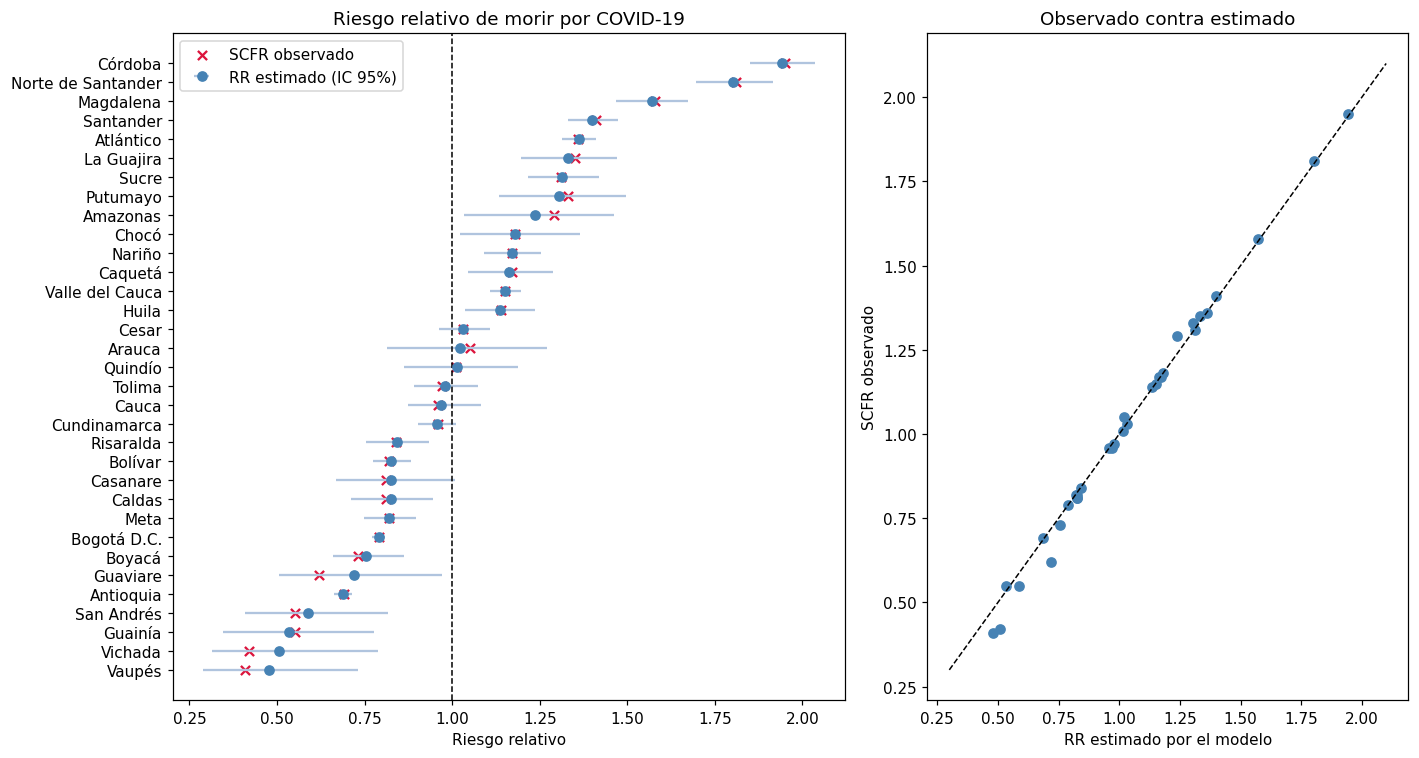

Error absoluto medio entre SCFR observado y RR estimado: 0.018


,departamento,SCFR_calculado,RR_estimado,RR_2.5%,RR_97.5%,P(R>1)
13,Córdoba,1.95,1.94,1.85,2.04,1.00
22,Norte de Santander,1.81,1.80,1.70,1.92,1.00
19,Magdalena,1.58,1.57,1.47,1.67,1.00
27,Santander,1.41,1.40,1.33,1.47,1.00
3,Atlántico,1.36,1.36,1.31,1.41,1.00
18,La Guajira,1.35,1.33,1.20,1.47,1.00
28,Sucre,1.31,1.31,1.22,1.42,1.00
23,Putumayo,1.33,1.31,1.13,1.50,1.00
0,Amazonas,1.29,1.24,1.04,1.46,0.99
12,Chocó,1.18,1.18,1.02,1.36,0.99


In [25]:
# Riesgo relativo de cada departamento: R_k = mu_k / E_k, calculado para cada muestra MCMC
mu_car = np.concatenate([c["mu"] for c in cadenas_car])
R_post = mu_car / E
datos["RR_estimado"] = np.median(R_post, axis=0)
datos["RR_2.5%"] = np.quantile(R_post, 0.025, axis=0)
datos["RR_97.5%"] = np.quantile(R_post, 0.975, axis=0)
datos["P(R>1)"] = np.mean(R_post > 1, axis=0)

# Figura 3 del informe: RR estimado vs SCFR observado
orden = datos.sort_values("RR_estimado")
fig, ax = plt.subplots(1, 2, figsize=(13, 7), gridspec_kw={"width_ratios": [1.4, 1]})
ax[0].errorbar(orden["RR_estimado"], orden["departamento"],
               xerr=[orden["RR_estimado"] - orden["RR_2.5%"], orden["RR_97.5%"] - orden["RR_estimado"]],
               fmt="o", color="steelblue", ecolor="lightsteelblue", label="RR estimado (IC 95%)")
ax[0].scatter(orden["SCFR_calculado"], orden["departamento"], color="crimson", marker="x", label="SCFR observado")
ax[0].axvline(1, color="black", ls="--", lw=1); ax[0].set_xlabel("Riesgo relativo"); ax[0].legend()
ax[0].set_title("Riesgo relativo de morir por COVID-19")

ax[1].scatter(datos["RR_estimado"], datos["SCFR_calculado"], color="steelblue")
lim = [0.3, 2.1]; ax[1].plot(lim, lim, "k--", lw=1)
ax[1].set_xlabel("RR estimado por el modelo"); ax[1].set_ylabel("SCFR observado")
ax[1].set_title("Observado contra estimado")
plt.tight_layout(); plt.savefig("riesgo_departamentos.pdf"); plt.show()

print("Error absoluto medio entre SCFR observado y RR estimado:",
      np.mean(np.abs(datos["SCFR_calculado"] - datos["RR_estimado"])).round(3))
datos[["departamento", "SCFR_calculado", "RR_estimado", "RR_2.5%", "RR_97.5%", "P(R>1)"]].sort_values("RR_estimado", ascending=False).round(2)

### Mapas (solo si el mapa se cargó en el paso 2)

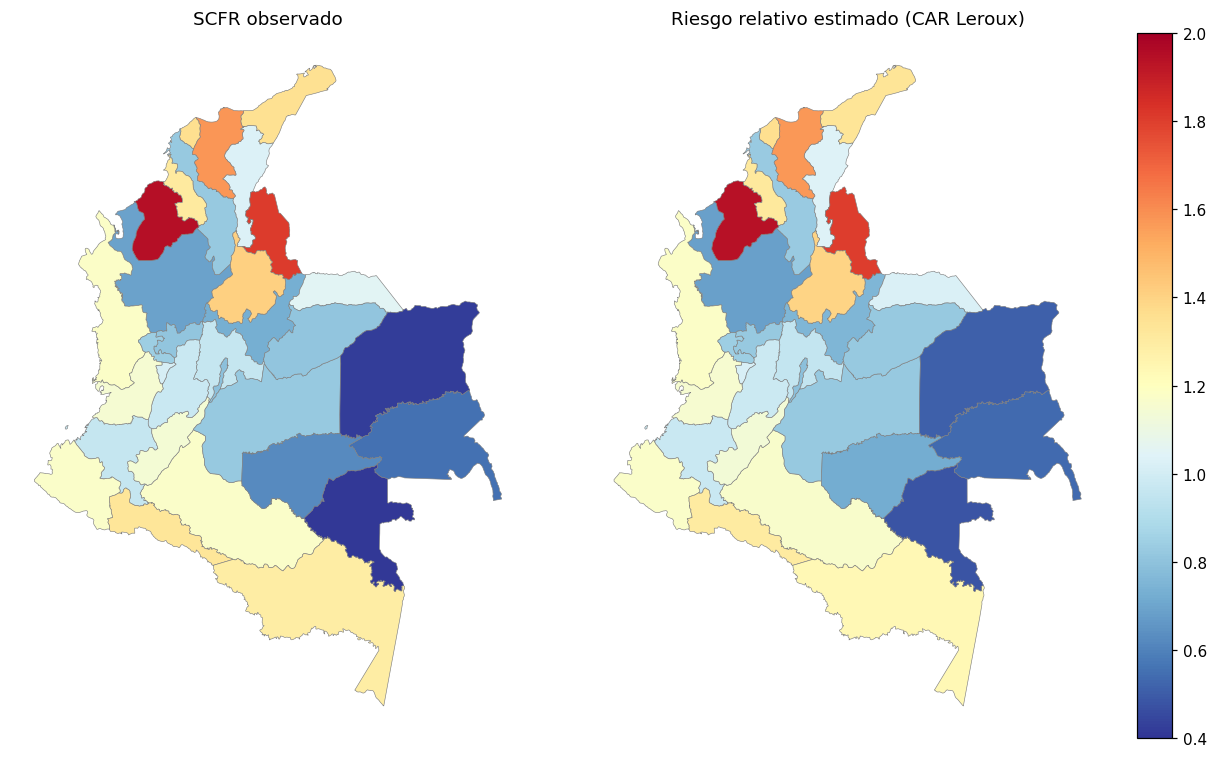

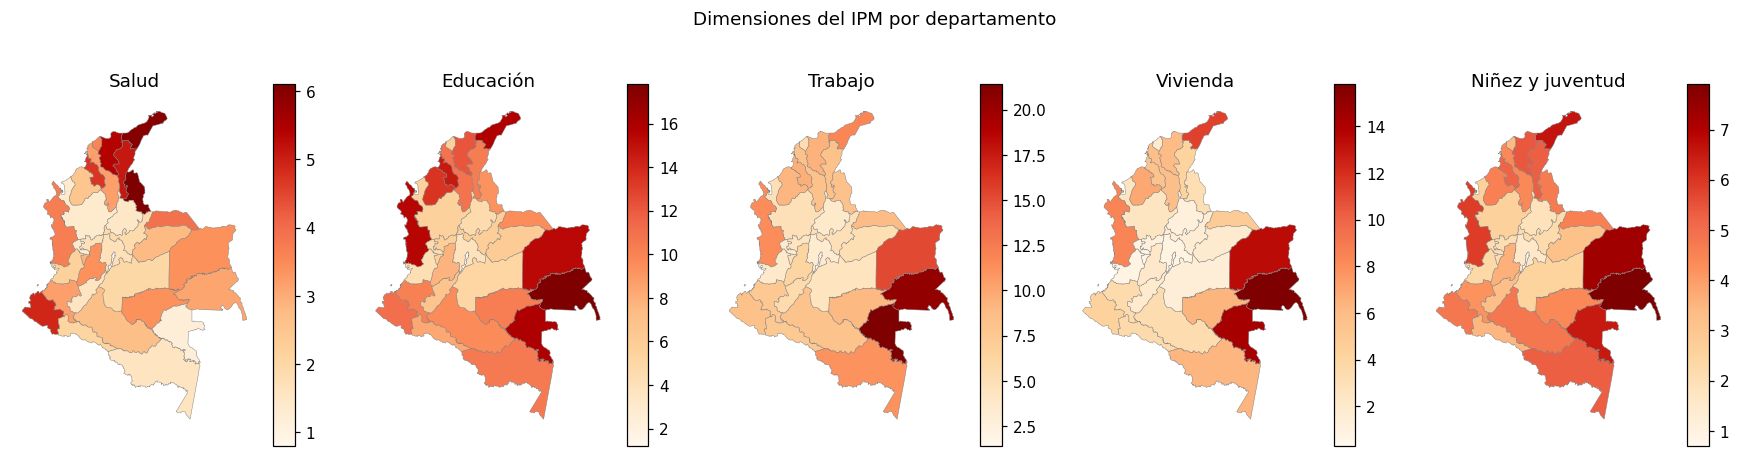

In [26]:
# Mapas complementarios: SCFR vs riesgo estimado y dimensiones del IPM
if mapa is not None:
    mapa_sin_sa = mapa[mapa["departamento"] != "San Andrés"]   # sin San Andrés, por escala

    # ---- Mapa 1: SCFR observado vs riesgo estimado ----
    mapa_d = mapa_sin_sa.merge(datos[["departamento", "SCFR_calculado", "RR_estimado"]], on="departamento")
    fig, ax = plt.subplots(1, 2, figsize=(12, 7))
    vmin, vmax = 0.4, 2.0
    mapa_d.plot(column="SCFR_calculado", cmap="RdYlBu_r", vmin=vmin, vmax=vmax, ax=ax[0], edgecolor="gray", lw=0.4)
    mapa_d.plot(column="RR_estimado", cmap="RdYlBu_r", vmin=vmin, vmax=vmax, ax=ax[1], edgecolor="gray", lw=0.4, legend=True)
    ax[0].set_title("SCFR observado"); ax[1].set_title("Riesgo relativo estimado (CAR Leroux)")
    for a_ in ax: a_.axis("off")
    plt.tight_layout(); plt.savefig("mapas.pdf", bbox_inches="tight"); plt.show()

    # ---- Mapa 2: dimensiones del IPM ----
    fig, ax = plt.subplots(1, 5, figsize=(16, 4.5))
    for a_, cov in zip(ax, covariables):
        mapa_sin_sa.merge(datos[["departamento", cov]], on="departamento").plot(
            column=cov, cmap="OrRd", ax=a_, edgecolor="gray", lw=0.3, legend=True)
        a_.set_title(nombres_cov[cov]); a_.axis("off")
    plt.suptitle("Dimensiones del IPM por departamento")
    plt.tight_layout(); plt.savefig("mapas_ipm.pdf", bbox_inches="tight"); plt.show()
else:
    print("No hay mapa disponible; usa el gráfico de riesgo por departamento del paso anterior.")

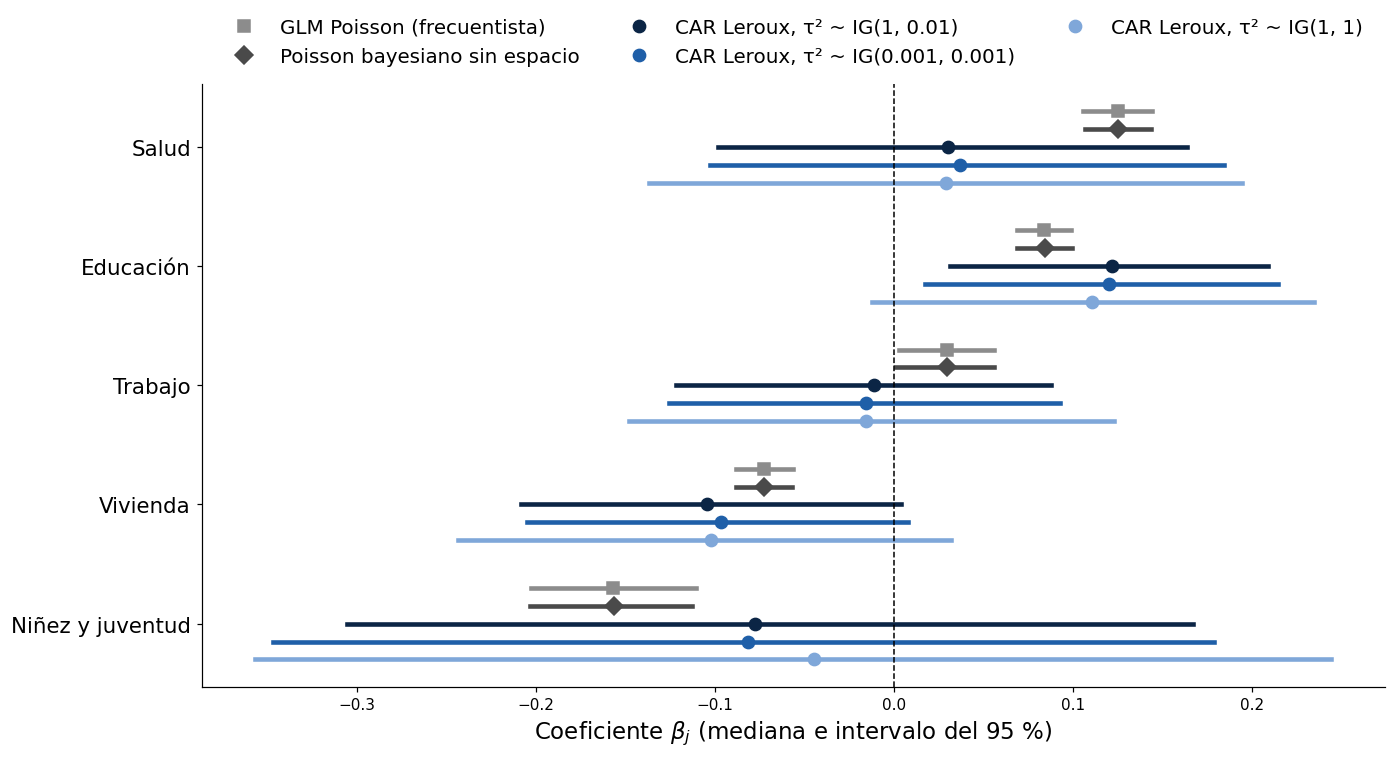

In [29]:
# Figura de sensibilidad: GLM, Poisson bayesiano y CAR con 3 prioris para tau2 (misma escala)
modelos_fig = {"GLM Poisson (frecuentista)": None,
               "Poisson bayesiano sin espacio": cadenas_poisson,
               "CAR Leroux, τ² ~ IG(1, 0.01)": cadenas_car,
               "CAR Leroux, τ² ~ IG(0.001, 0.001)": cadenas_vaga,
               "CAR Leroux, τ² ~ IG(1, 1)": cadenas_inf}
col = ["#8C8C8C", "#4A4A4A", "#0B2545", "#1F5FA8", "#7FA7D9"]; mk = ["s", "D", "o", "o", "o"]
off = np.linspace(-0.3, 0.3, len(modelos_fig))
fig, ax = plt.subplots(figsize=(13, 7))
for i, (nombre, cad) in enumerate(modelos_fig.items()):
    for j in range(5):
        if cad is None:                      # GLM: estimación e IC del 95 %
            m = glm.params[j + 1]; lo, hi = glm.conf_int()[j + 1]
        else:                                # bayesianos: mediana e intervalo de credibilidad del 95 %
            mu = juntar(cad, "beta", j + 1).ravel()
            m, lo, hi = np.median(mu), np.quantile(mu, 0.025), np.quantile(mu, 0.975)
        ax.plot([lo, hi], [j + off[i]] * 2, color=col[i], lw=3)
        ax.plot(m, j + off[i], mk[i], color=col[i], ms=8, label=nombre if j == 0 else None)
ax.axvline(0, color="black", ls="--", lw=1)
ax.set_yticks(range(5)); ax.set_yticklabels([nombres_cov[c] for c in covariables], fontsize=14); ax.invert_yaxis()
ax.set_xlabel(r"Coeficiente $\beta_j$ (mediana e intervalo del 95 %)", fontsize=15)
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=3, frameon=False, fontsize=13)
for s in ["top", "right"]: ax.spines[s].set_visible(False)
plt.tight_layout(); plt.savefig("sensibilidad.png", dpi=200); plt.savefig("sensibilidad.pdf"); plt.show()

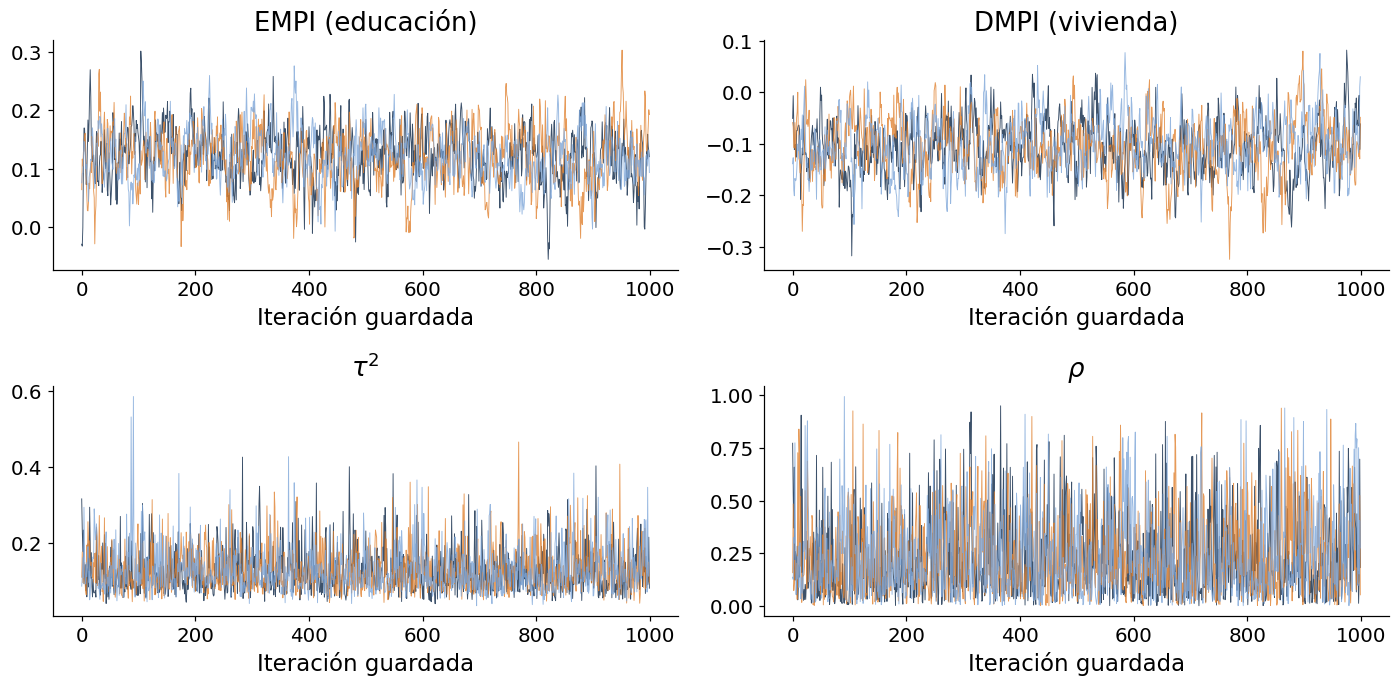

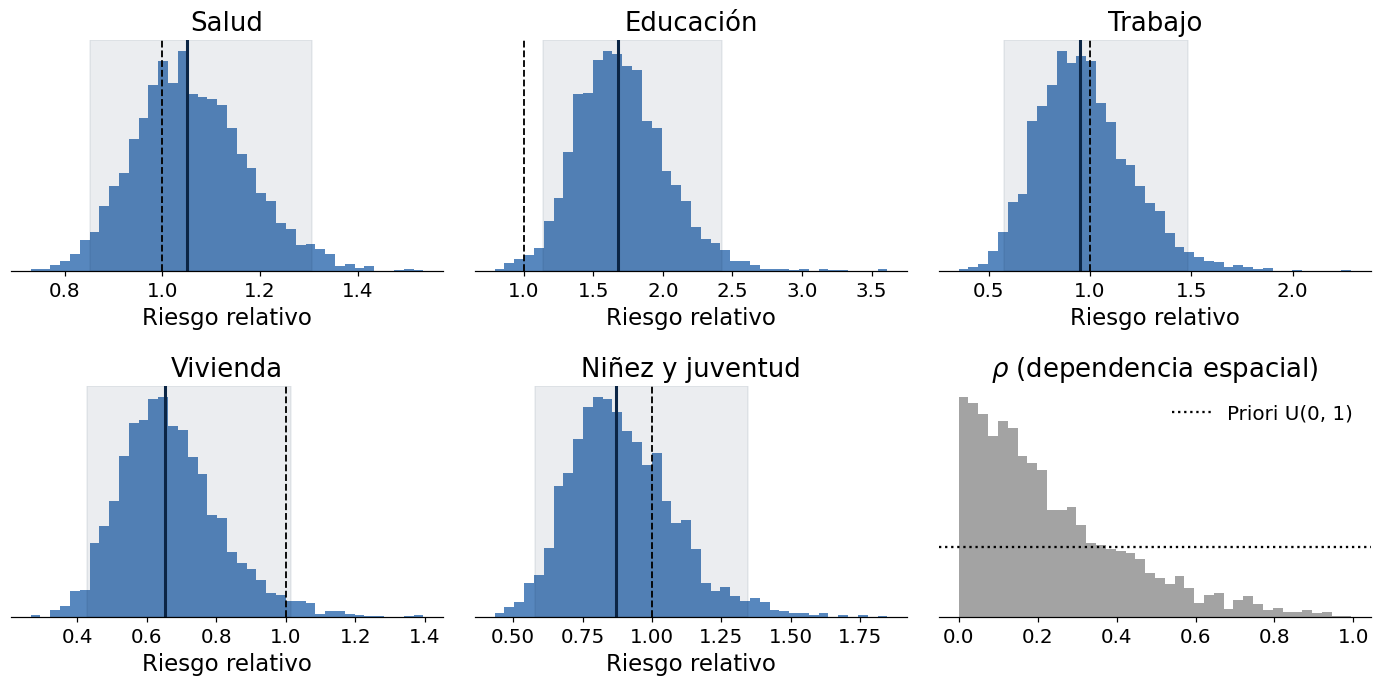

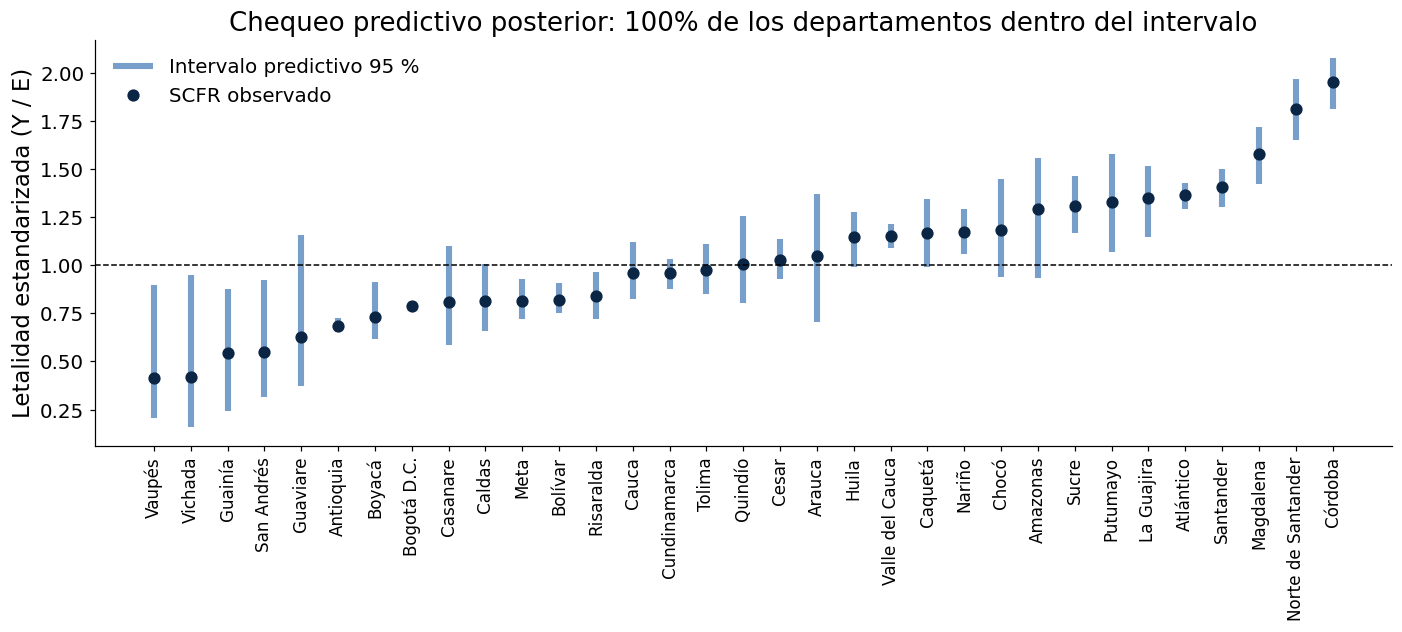

Proporción de departamentos dentro del intervalo predictivo del 95 %: 1.0


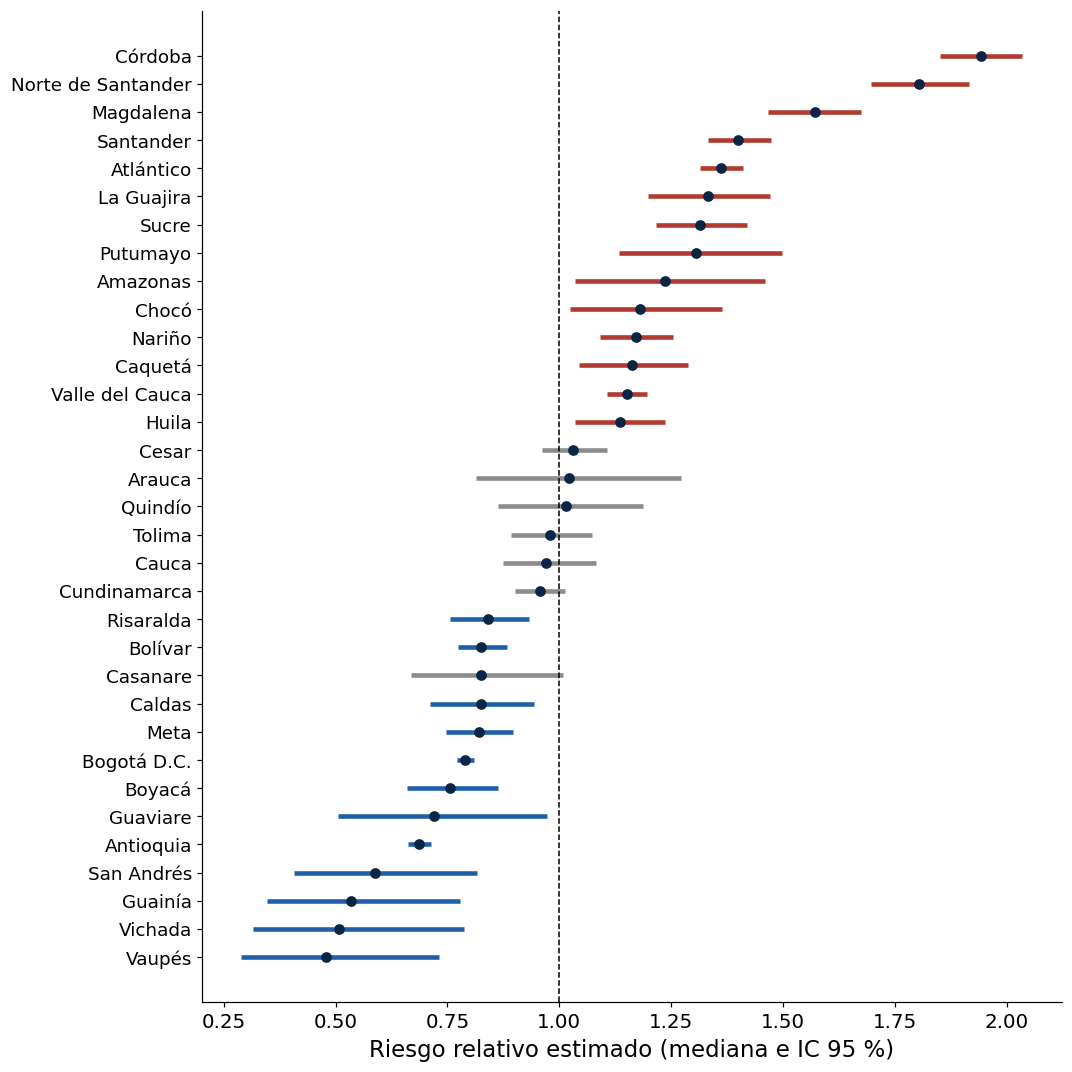

In [ ]:
#Graficas para la presentación de resultados
# # Genera: fig_trazas, fig_posteriores_rr, fig_ppc, fig_riesgo (en .png y .pdf)
# =====================================================================
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({"font.size": 15, "axes.titlesize": 17, "axes.labelsize": 15,
                     "xtick.labelsize": 13, "ytick.labelsize": 13, "legend.fontsize": 13})
AZUL, ACENTO, GRIS = "#0B2545", "#1F5FA8", "#8C8C8C"
colores_cadena = ["#0B2545", "#E0812F", "#7FA7D9"]
desv_est = X_original.std(axis=0, ddof=1)

# ---- 1) Trazas de los parámetros clave (3 cadenas) ----
fig, ax = plt.subplots(2, 2, figsize=(13, 6.5))
param_traza = [("EMPI (educación)", "beta", 2), ("DMPI (vivienda)", "beta", 4),
               (r"$\tau^2$", "tau2", None), (r"$\rho$", "rho", None)]
for a_, (nombre, clave, j) in zip(ax.ravel(), param_traza):
    for c, col in zip(juntar(cadenas_car, clave, j), colores_cadena):
        a_.plot(c, lw=0.6, color=col, alpha=0.8)
    a_.set_title(nombre); a_.set_xlabel("Iteración guardada")
    for s in ["top", "right"]: a_.spines[s].set_visible(False)
plt.tight_layout(); plt.savefig("fig_trazas.png", dpi=200); plt.savefig("fig_trazas.pdf"); plt.show()

# ---- 2) Posteriores de los riesgos relativos (1 desviación estándar) y de rho ----
fig, ax = plt.subplots(2, 3, figsize=(13, 6.5))
for a_, j in zip(ax.ravel()[:5], range(5)):
    rr = np.exp(juntar(cadenas_car, "beta", j + 1).ravel() * desv_est[j])
    lo, med, hi = np.quantile(rr, [0.025, 0.5, 0.975])
    a_.hist(rr, bins=40, density=True, color=ACENTO, alpha=0.75)
    a_.axvspan(lo, hi, color=AZUL, alpha=0.08)            # intervalo de credibilidad del 95 %
    a_.axvline(1, color="black", ls="--", lw=1.2)          # RR = 1: sin efecto
    a_.axvline(med, color=AZUL, lw=2)
    a_.set_title(nombres_cov[covariables[j]]); a_.set_yticks([])
    a_.set_xlabel("Riesgo relativo")
    for s in ["top", "right", "left"]: a_.spines[s].set_visible(False)
rho_m = juntar(cadenas_car, "rho").ravel()
ax[1, 2].hist(rho_m, bins=40, density=True, color=GRIS, alpha=0.8)
ax[1, 2].axhline(1, color="black", ls=":", lw=1.5, label="Priori U(0, 1)")
ax[1, 2].set_title(r"$\rho$ (dependencia espacial)"); ax[1, 2].set_yticks([]); ax[1, 2].legend(frameon=False)
for s in ["top", "right", "left"]: ax[1, 2].spines[s].set_visible(False)
plt.tight_layout(); plt.savefig("fig_posteriores_rr.png", dpi=200); plt.savefig("fig_posteriores_rr.pdf"); plt.show()

# ---- 3) Chequeo predictivo posterior: Y_rep ~ Poisson(mu^(s)) ----
rng_ppc = np.random.default_rng(2026)
mu_s = np.concatenate([c["mu"] for c in cadenas_car])          # (muestras x 33)
y_rep = rng_ppc.poisson(mu_s)
scfr_rep = y_rep / E
lo_r, hi_r = np.quantile(scfr_rep, [0.025, 0.975], axis=0)
dentro = np.mean((y / E >= lo_r) & (y / E <= hi_r))
orden_ppc = np.argsort(y / E)
fig, ax = plt.subplots(figsize=(13, 6))
xs = np.arange(K)
ax.vlines(xs, lo_r[orden_ppc], hi_r[orden_ppc], color=ACENTO, lw=4, alpha=0.6, label="Intervalo predictivo 95 %")
ax.plot(xs, (y / E)[orden_ppc], "o", color=AZUL, ms=7, label="SCFR observado")
ax.axhline(1, color="black", ls="--", lw=1)
ax.set_xticks(xs); ax.set_xticklabels(datos["departamento"].values[orden_ppc], rotation=90, fontsize=11)
ax.set_ylabel("Letalidad estandarizada (Y / E)")
ax.set_title(f"Chequeo predictivo posterior: {dentro:.0%} de los departamentos dentro del intervalo")
ax.legend(frameon=False, loc="upper left")
for s in ["top", "right"]: ax.spines[s].set_visible(False)
plt.tight_layout(); plt.savefig("fig_ppc.png", dpi=200); plt.savefig("fig_ppc.pdf"); plt.show()
print("Proporción de departamentos dentro del intervalo predictivo del 95 %:", round(dentro, 3))

# ---- 4) Riesgo relativo por departamento con P(R > 1) ----
R_s = mu_s / E
med_R = np.median(R_s, axis=0); lo_R, hi_R = np.quantile(R_s, [0.025, 0.975], axis=0)
P_R = np.mean(R_s > 1, axis=0)
o = np.argsort(med_R)
fig, ax = plt.subplots(figsize=(10, 10))
yy = np.arange(K)
col_p = np.where(P_R[o] >= 0.99, "#B23A2E", np.where(P_R[o] <= 0.03, ACENTO, GRIS))
ax.hlines(yy, lo_R[o], hi_R[o], color=col_p, lw=3)
ax.plot(med_R[o], yy, "o", color=AZUL, ms=6)
ax.axvline(1, color="black", ls="--", lw=1)
ax.set_yticks(yy); ax.set_yticklabels(datos["departamento"].values[o], fontsize=12)
ax.set_xlabel("Riesgo relativo estimado (mediana e IC 95 %)")
for s in ["top", "right"]: ax.spines[s].set_visible(False)
plt.tight_layout(); plt.savefig("fig_riesgo.png", dpi=200); plt.savefig("fig_riesgo.pdf"); plt.show()

## Resumen de resultados para el informe

Esta celda imprime en un solo lugar los números que van en el documento.

In [ ]:
# Resumen final de los resultados principales
print("=== RESUMEN ===")
print(f"Índice de dispersión del GLM: {dispersion:.1f}")
I_res = prueba_moran(glm.resid_pearson, W)
print(f"Moran residuos GLM: I = {I_res[0]:.3f}, p(positiva) = {I_res[2]:.4f}, p(negativa) = {I_res[3]:.4f}")
print(f"DIC sin espacio = {dic_poisson:.1f} | DIC CAR = {dic_car:.1f}")
print(f"rho: mediana {post_car.loc['rho', 'Mediana']:.3f}, IC 95% ({post_car.loc['rho', '2.5%']:.3f}, {post_car.loc['rho', '97.5%']:.3f})")
print(f"Máximo R-hat: {post_car['R-hat'].max():.3f} | Mínimo n efectivo: {post_car['n efectivo'].min():.0f} | Geweke en [-2, 2]: {post_car['Geweke'].abs().max() < 2}")
print("\nRiesgos relativos (CAR):")
print(rr_car[["RR mediana", "2.5%", "97.5%", "P(RR > 1)"]].astype(float).round(2))

=== RESUMEN ===
Índice de dispersión del GLM: 54.9
Moran residuos GLM: I = -0.258, p(positiva) = 0.9923, p(negativa) = 0.0077
DIC sin espacio = 1677.1 | DIC CAR = 312.7
rho: mediana 0.183, IC 95% (0.008, 0.730)
Máximo R-hat: 1.002 | Mínimo n efectivo: 494 | Geweke en [-2, 2]: False

Riesgos relativos (CAR):
                         RR mediana  2.5%  97.5%  P(RR > 1)
HMPI (Salud)                   1.05  0.85   1.31       0.68
EMPI (Educación)               1.68  1.14   2.43       0.99
WMPI (Trabajo)                 0.95  0.58   1.49       0.41
DMPI (Vivienda)                0.65  0.43   1.02       0.03
YMPI (Niñez y juventud)        0.87  0.58   1.35       0.27
